# ISIC 2019 Skin Lesion Classification Using Deep Learning

This project focuses on classifying dermoscopic skin lesion images into nine different diagnostic categories using deep learning.

The project compares:
- A custom CNN trained from scratch
- ResNet50 using transfer learning
- EfficientNet-B0 using transfer learning
- DenseNet121 using transfer learning

The models are evaluated using accuracy, precision, recall, F1-score, mean sensitivity, and confusion matrices.

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU: True
Device: Tesla T4


In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"khushipopli","key":"edae64d784777649a54da152385f15a3"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d syedibrarhussain/isic-2019-skin-cancer-detection-dataset

Dataset URL: https://www.kaggle.com/datasets/syedibrarhussain/isic-2019-skin-cancer-detection-dataset
License(s): CC-BY-NC-SA-4.0
100% 785M/785M [00:07<00:00, 113MB/s]



In [ ]:
!mkdir -p /content/isic

In [ ]:
!unzip -q *.zip -d /content/isic

In [ ]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
train_dir = "/content/isic/Train/Train"
test_dir = "/content/isic/Test/Test"

In [ ]:
print(train_dir)
print(test_dir)

/content/isic/Train/Train
/content/isic/Test/Test


In [ ]:
train_data = datasets.ImageFolder(train_dir)

In [ ]:
print("Classes:", train_data.classes)
print("Number of images:", len(train_data))

Classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']
Number of images: 2239


In [ ]:
print(train_data.class_to_idx)

{'actinic keratosis': 0, 'basal cell carcinoma': 1, 'dermatofibroma': 2, 'melanoma': 3, 'nevus': 4, 'pigmented benign keratosis': 5, 'seborrheic keratosis': 6, 'squamous cell carcinoma': 7, 'vascular lesion': 8}


In [ ]:
test_data = datasets.ImageFolder(test_dir)

In [ ]:
print("Test images:", len(test_data))
print("Test classes:", test_data.classes)

Test images: 118
Test classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']


In [ ]:
image, label = train_data[0]

print("Image shape:", image.size)
print("Label:", label)
print("Class:", train_data.classes[label])

Image shape: (600, 450)
Label: 0
Class: actinic keratosis


STEP 4

In [ ]:
from collections import Counter

counts = Counter(train_data.targets)

for i, count in sorted(counts.items()):
    print(f"{train_data.classes[i]}: {count}")

actinic keratosis: 114
basal cell carcinoma: 376
dermatofibroma: 95
melanoma: 438
nevus: 357
pigmented benign keratosis: 462
seborrheic keratosis: 77
squamous cell carcinoma: 181
vascular lesion: 139


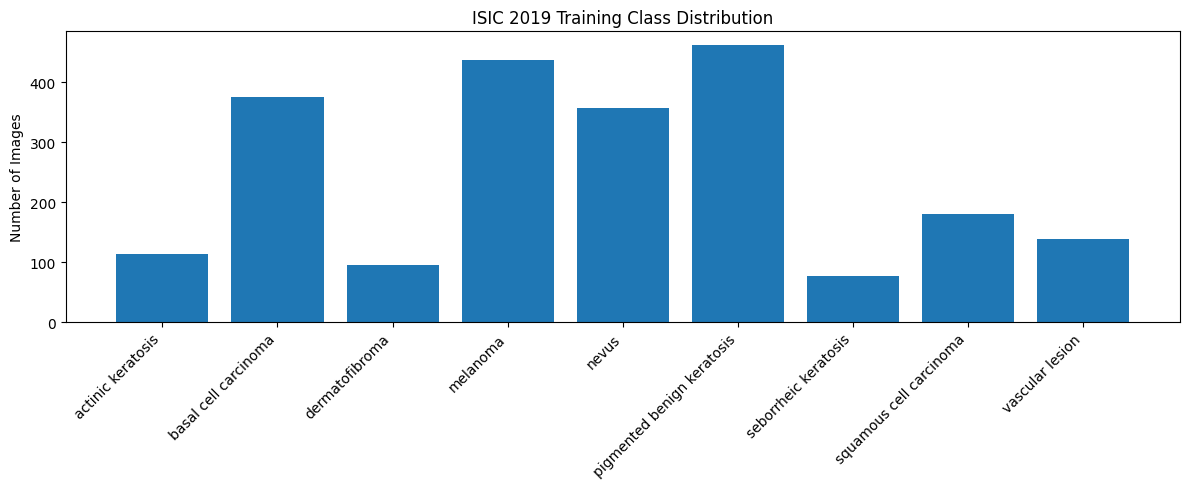

In [ ]:
classes = train_data.classes
counts = [counts[i] for i in range(len(classes))]

plt.figure(figsize=(12, 5))
plt.bar(classes, counts)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of Images")
plt.title("ISIC 2019 Training Class Distribution")

plt.tight_layout()
plt.show()

In [ ]:
total = sum(counts)

for cls, count in zip(classes, counts):
    print(f"{cls}: {count} ({count/total*100:.2f}%)")

actinic keratosis: 114 (5.09%)
basal cell carcinoma: 376 (16.79%)
dermatofibroma: 95 (4.24%)
melanoma: 438 (19.56%)
nevus: 357 (15.94%)
pigmented benign keratosis: 462 (20.63%)
seborrheic keratosis: 77 (3.44%)
squamous cell carcinoma: 181 (8.08%)
vascular lesion: 139 (6.21%)


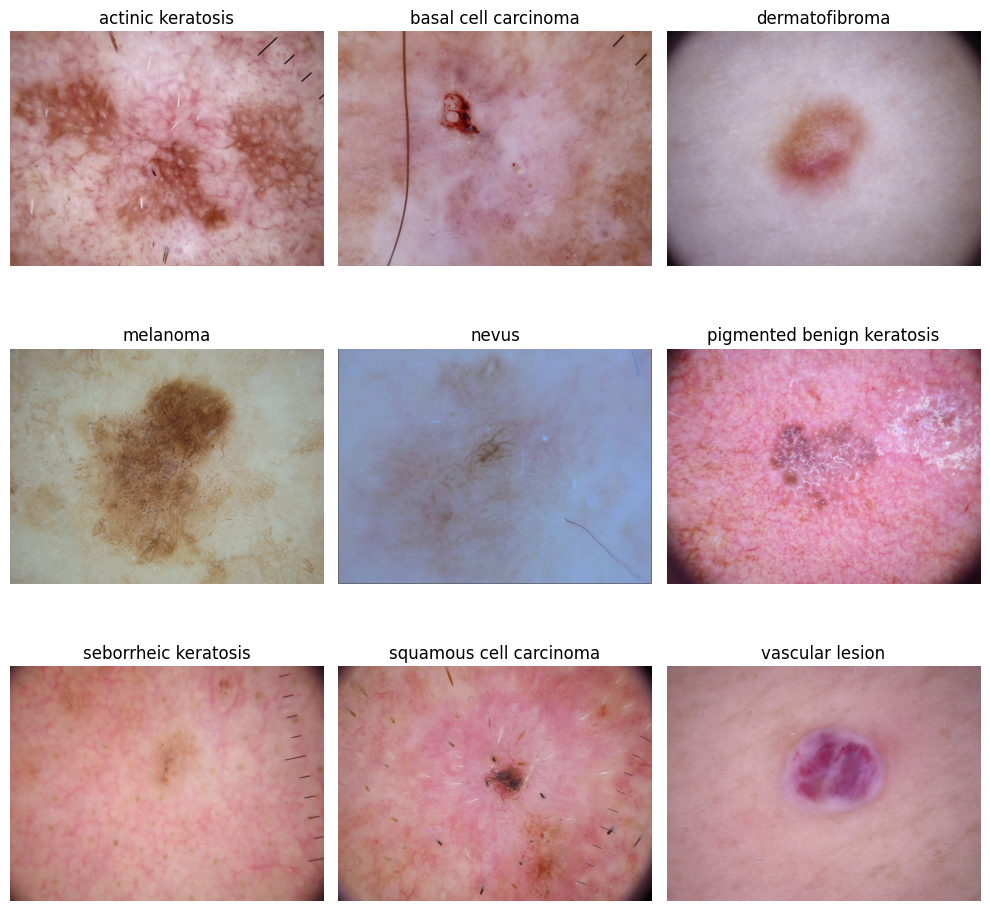

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    class_name = train_data.classes[i]

    # find indices belonging to this class, pick one at random
    class_indices = [j for j, (_, label) in enumerate(train_data.samples) if label == i]
    idx = np.random.choice(class_indices)

    image, label = train_data[idx]
    ax.imshow(image)
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

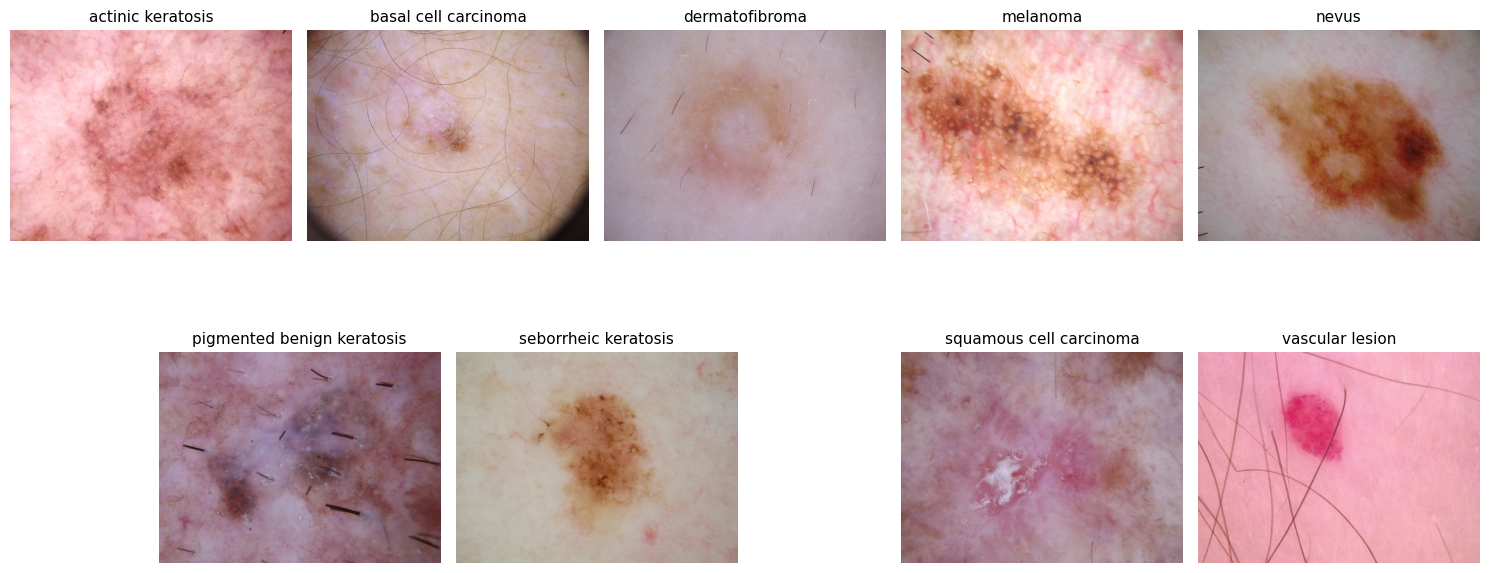

In [ ]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(15, 7))
gs = gridspec.GridSpec(2, 10, figure=fig)  # 10 columns = LCM-friendly for 5 and 4

class_to_indices = {}
for j, (_, label) in enumerate(train_data.samples):
    class_to_indices.setdefault(label, []).append(j)

# Row 1: 5 images, each spanning 2 of the 10 columns
for i in range(5):
    ax = fig.add_subplot(gs[0, i*2:i*2+2])
    class_name = train_data.classes[i]
    idx = np.random.choice(class_to_indices[i])
    image, label = train_data[idx]
    ax.imshow(image)
    ax.set_title(train_data.classes[label], fontsize=11)
    ax.axis("off")

# Row 2: 4 images, each spanning 2.5 columns — offset to center them
for i in range(4):
    ax = fig.add_subplot(gs[1, int(i*2.5)+1:int(i*2.5)+3])
    class_idx = i + 5
    idx = np.random.choice(class_to_indices[class_idx])
    image, label = train_data[idx]
    ax.imshow(image)
    ax.set_title(train_data.classes[label], fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

STEP 5

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
indices = np.arange(len(train_data))
labels = np.array(train_data.targets)

print("Total:", len(indices))

Total: 2239


In [ ]:
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

In [ ]:
print("Training:", len(train_idx))
print("Validation:", len(val_idx))

Training: 1791
Validation: 448


In [ ]:
print("Training distribution:")

for i in range(9):
    print(train_data.classes[i], np.sum(labels[train_idx] == i))

print("\nValidation distribution:")

for i in range(9):
    print(train_data.classes[i], np.sum(labels[val_idx] == i))

Training distribution:
actinic keratosis 91
basal cell carcinoma 301
dermatofibroma 76
melanoma 350
nevus 286
pigmented benign keratosis 369
seborrheic keratosis 62
squamous cell carcinoma 145
vascular lesion 111

Validation distribution:
actinic keratosis 23
basal cell carcinoma 75
dermatofibroma 19
melanoma 88
nevus 71
pigmented benign keratosis 93
seborrheic keratosis 15
squamous cell carcinoma 36
vascular lesion 28


In [ ]:
test_counts = Counter(test_data.targets)

for i, count in sorted(test_counts.items()):
    print(f"{test_data.classes[i]}: {count}")

actinic keratosis: 16
basal cell carcinoma: 16
dermatofibroma: 16
melanoma: 16
nevus: 16
pigmented benign keratosis: 16
seborrheic keratosis: 3
squamous cell carcinoma: 16
vascular lesion: 3


STEP 6

In [ ]:
from torchvision import transforms

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_transform = val_transform

In [ ]:
from torchvision import datasets
from torch.utils.data import Subset

train_full = datasets.ImageFolder(train_dir, transform=train_transform)
val_full = datasets.ImageFolder(train_dir, transform=val_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)

train_dataset = Subset(train_full, train_idx)
val_dataset = Subset(val_full, val_idx)

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

In [ ]:
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

images, labels_batch = next(iter(train_loader))

print("Image batch:", images.shape)
print("Label batch:", labels_batch.shape)

Train: 1791
Validation: 448
Test: 118
Image batch: torch.Size([32, 3, 224, 224])
Label batch: torch.Size([32])


STEP 7

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(9),
    y=labels[train_idx]
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print(class_weights)

tensor([2.1868, 0.6611, 2.6184, 0.5686, 0.6958, 0.5393, 3.2097, 1.3724, 1.7928])


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_weights = class_weights.to(device)

print(device)

cuda


In [ ]:
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 9)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
model = CustomCNN().to(device)

print(model)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [ ]:
total_params = sum(p.numel() for p in model.parameters())

print("Total parameters:", total_params)

Total parameters: 391689


In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
images, labels_batch = next(iter(train_loader))

images = images.to(device)

output = model(images)

print("Input:", images.shape)
print("Output:", output.shape)

Input: torch.Size([32, 3, 224, 224])
Output: torch.Size([32, 9])


In [ ]:
print(torch.cuda.get_device_name(0))
print(
    round(torch.cuda.memory_allocated() / 1024**2, 2),
    "MB allocated"
)

Tesla T4
1034.05 MB allocated


STEP 8

In [ ]:
EPOCHS = 20
best_val_loss = float("inf")
patience = 4
patience_counter = 0

In [ ]:
def calculate_accuracy(outputs, labels):
    predictions = torch.argmax(outputs, dim=1)
    return (predictions == labels).float().mean().item()

In [ ]:
from PIL import Image

bad_images = []

for path, label in train_full.samples:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as e:
        bad_images.append((path, str(e)))

print("Bad images:", len(bad_images))

for item in bad_images:
    print(item)

Bad images: 0


In [ ]:
from PIL import Image

bad_images = []

for path, label in train_full.samples:
    try:
        with Image.open(path) as img:
            img.convert("RGB").load()
    except Exception as e:
        bad_images.append((path, str(e)))

print("Bad images:", len(bad_images))

for path, error in bad_images:
    print("\n", path)
    print(error)

Bad images: 1

 /content/isic/Train/Train/melanoma/ISIC_0000526.jpg
broken data stream when reading image file


In [ ]:
bad_path = bad_images[0][0]

clean_samples = [
    sample for sample in train_full.samples
    if sample[0] != bad_path
]

print("Original images:", len(train_full.samples))
print("Clean images:", len(clean_samples))
print("Removed:", len(train_full.samples) - len(clean_samples))

Original images: 2239
Clean images: 2238
Removed: 1


In [ ]:
clean_labels = np.array([label for path, label in clean_samples])

print("Clean labels:", len(clean_labels))

Clean labels: 2238


In [ ]:
from sklearn.model_selection import train_test_split

clean_indices = np.arange(len(clean_samples))

train_idx, val_idx = train_test_split(
    clean_indices,
    test_size=0.20,
    random_state=42,
    stratify=clean_labels
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))

Training: 1790
Validation: 448


In [ ]:
from torch.utils.data import Dataset

class CleanImageFolder(Dataset):

    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]

        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_full = CleanImageFolder(
    clean_samples,
    transform=train_transform
)

val_full = CleanImageFolder(
    clean_samples,
    transform=val_transform
)

train_dataset = Subset(train_full, train_idx)
val_dataset = Subset(val_full, val_idx)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 1790
Validation dataset: 448


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [ ]:
images, labels_batch = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels_batch.shape)

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(9),
    y=clean_labels[train_idx]
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
).to(device)

print("Class weights:")
print(class_weights)

Class weights:
tensor([2.1856, 0.6608, 2.6170, 0.5699, 0.6954, 0.5390, 3.2079, 1.3716, 1.7918],
       device='cuda:0')


In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

In [ ]:
EPOCHS = 20
best_val_loss = float("inf")
patience = 4
patience_counter = 0

for epoch in range(EPOCHS):

    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels_batch in train_loader:

        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)
        train_correct += (predictions == labels_batch).sum().item()
        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels_batch in val_loader:

            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)
            val_correct += (predictions == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "best_custom_cnn.pth"
        )

        print("  ✓ Best model saved")

    else:

        patience_counter += 1

        if patience_counter >= patience:
            print("  Early stopping")
            break

Epoch [1/20] Train Loss: 1.9306 Train Acc: 0.2447 Val Loss: 1.8184 Val Acc: 0.2500
  ✓ Best model saved
Epoch [2/20] Train Loss: 1.8327 Train Acc: 0.2743 Val Loss: 1.7431 Val Acc: 0.2902
  ✓ Best model saved
Epoch [3/20] Train Loss: 1.7663 Train Acc: 0.3022 Val Loss: 1.6938 Val Acc: 0.3237
  ✓ Best model saved


KeyboardInterrupt: 

In [ ]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(256, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(512, 9)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [ ]:
model = ImprovedCNN().to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=Tru

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [ ]:
EPOCHS = 25
best_val_loss = float("inf")
patience = 5
patience_counter = 0

for epoch in range(EPOCHS):

    # TRAIN
    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels_batch in train_loader:

        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)
        train_correct += (predictions == labels_batch).sum().item()
        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # VALIDATION
    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels_batch in val_loader:

            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)
            val_correct += (predictions == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    scheduler.step(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "best_improved_cnn.pth"
        )

        print("  ✓ Best model saved")

    else:

        patience_counter += 1

        if patience_counter >= patience:
            print("  Early stopping")
            break

Epoch [1/25] Train Loss: 1.8958 Train Acc: 0.2419 Val Loss: 1.7742 Val Acc: 0.2478
  ✓ Best model saved
Epoch [2/25] Train Loss: 1.7374 Train Acc: 0.3196 Val Loss: 1.8567 Val Acc: 0.2991
Epoch [3/25] Train Loss: 1.7063 Train Acc: 0.3190 Val Loss: 1.6533 Val Acc: 0.3527
  ✓ Best model saved
Epoch [4/25] Train Loss: 1.7036 Train Acc: 0.3268 Val Loss: 1.7164 Val Acc: 0.2902
Epoch [5/25] Train Loss: 1.6740 Train Acc: 0.3240 Val Loss: 1.7438 Val Acc: 0.2143
Epoch [6/25] Train Loss: 1.6203 Train Acc: 0.3486 Val Loss: 1.6258 Val Acc: 0.2500
  ✓ Best model saved
Epoch [7/25] Train Loss: 1.5875 Train Acc: 0.3581 Val Loss: 1.7042 Val Acc: 0.2790
Epoch [8/25] Train Loss: 1.6110 Train Acc: 0.3637 Val Loss: 1.7014 Val Acc: 0.3482
Epoch [9/25] Train Loss: 1.5775 Train Acc: 0.3737 Val Loss: 1.5794 Val Acc: 0.3638
  ✓ Best model saved
Epoch [10/25] Train Loss: 1.5590 Train Acc: 0.3682 Val Loss: 1.5962 Val Acc: 0.3527
Epoch [11/25] Train Loss: 1.5395 Train Acc: 0.3620 Val Loss: 1.5733 Val Acc: 0.3170
 

In [ ]:
model.load_state_dict(
    torch.load(
        "best_improved_cnn.pth",
        map_location=device
    )
)

model.eval()

print("Best saved Improved CNN loaded.")

Best saved Improved CNN loaded.


In [ ]:
y_true = []
y_pred = []

with torch.no_grad():

    for images, labels_batch in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels_batch.numpy())
        y_pred.extend(predictions.cpu().numpy())

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.3929
Precision: 0.4196
Recall:    0.4308
F1 Score:  0.3721


In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(9)
)

sensitivity_per_class = []

for i in range(9):

    TP = cm[i, i]
    FN = cm[i, :].sum() - TP

    sensitivity = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else 0
    )

    sensitivity_per_class.append(sensitivity)

mean_sensitivity = np.mean(
    sensitivity_per_class
)

print(
    f"Mean Sensitivity: "
    f"{mean_sensitivity:.4f}"
)

Mean Sensitivity: 0.4308


## Transfer Learning — ResNet50

Transfer learning uses a model that has already been trained on a large image dataset and adapts it to the current classification task.

Instead of learning all visual features from scratch, the pretrained model already contains useful features such as edges, textures, shapes, and patterns.

In this project, ResNet50 pretrained on ImageNet is adapted for classification of the nine ISIC 2019 skin lesion classes.

The final classification layer is replaced with a new layer containing nine outputs.

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights

In [ ]:
weights = ResNet50_Weights.DEFAULT

resnet = resnet50(weights=weights)

print("ResNet50 loaded successfully.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


ResNet50 loaded successfully.


In [ ]:
import torch.nn as nn

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    9
)

print(resnet.fc)

Linear(in_features=2048, out_features=9, bias=True)


In [ ]:
resnet = resnet.to(device)

print("ResNet50 device:", device)

ResNet50 device: cuda


In [ ]:
for param in resnet.parameters():
    param.requires_grad = False

for param in resnet.fc.parameters():
    param.requires_grad = True

In [ ]:
trainable_params = sum(
    p.numel()
    for p in resnet.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in resnet.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 23526473
Trainable parameters: 18441


In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    resnet.fc.parameters(),
    lr=0.001
)

In [ ]:
images, labels_batch = next(iter(train_loader))

images = images.to(device)

outputs = resnet(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 9])


## ResNet50 Feature Extraction

In the first stage of transfer learning, the pretrained ResNet50 feature extractor is kept frozen and only the newly added nine-class classification layer is trained.

This allows the new classifier to learn how to map the pretrained visual features to the nine ISIC skin lesion classes without significantly modifying the pretrained weights.

In [ ]:
EPOCHS = 8

best_val_loss = float("inf")
patience = 3
patience_counter = 0

for epoch in range(EPOCHS):

    # -------- TRAINING --------
    resnet.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels_batch in train_loader:

        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = resnet(images)
        loss = criterion(outputs, labels_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        train_correct += (
            predictions == labels_batch
        ).sum().item()

        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # -------- VALIDATION --------
    resnet.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels_batch in val_loader:

            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = resnet(images)
            loss = criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (
                predictions == labels_batch
            ).sum().item()

            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total


    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )


    # -------- SAVE BEST MODEL --------
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            resnet.state_dict(),
            "best_resnet_stage1.pth"
        )

        print("  ✓ Best model saved")

    else:

        patience_counter += 1

        if patience_counter >= patience:
            print("  Early stopping")
            break

Epoch [1/8] Train Loss: 1.9709 Train Acc: 0.3089 Val Loss: 1.7569 Val Acc: 0.3549
  ✓ Best model saved
Epoch [2/8] Train Loss: 1.6474 Train Acc: 0.4581 Val Loss: 1.5706 Val Acc: 0.4777
  ✓ Best model saved
Epoch [3/8] Train Loss: 1.4987 Train Acc: 0.4855 Val Loss: 1.5030 Val Acc: 0.4397
  ✓ Best model saved
Epoch [4/8] Train Loss: 1.3810 Train Acc: 0.5184 Val Loss: 1.4206 Val Acc: 0.5022
  ✓ Best model saved
Epoch [5/8] Train Loss: 1.3091 Train Acc: 0.5447 Val Loss: 1.3674 Val Acc: 0.4866
  ✓ Best model saved
Epoch [6/8] Train Loss: 1.2674 Train Acc: 0.5341 Val Loss: 1.3358 Val Acc: 0.4710
  ✓ Best model saved
Epoch [7/8] Train Loss: 1.2024 Train Acc: 0.5793 Val Loss: 1.2905 Val Acc: 0.5223
  ✓ Best model saved
Epoch [8/8] Train Loss: 1.1911 Train Acc: 0.5709 Val Loss: 1.2724 Val Acc: 0.4978
  ✓ Best model saved


In [ ]:
resnet.load_state_dict(
    torch.load(
        "best_resnet_stage1.pth",
        map_location=device
    )
)

print("Best Stage 1 ResNet50 loaded.")

Best Stage 1 ResNet50 loaded.


In [ ]:
for param in resnet.parameters():
    param.requires_grad = True

print("All ResNet50 layers are now trainable.")

All ResNet50 layers are now trainable.


In [ ]:
trainable_params = sum(
    p.numel()
    for p in resnet.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 23526473


In [ ]:
optimizer = torch.optim.Adam(
    resnet.parameters(),
    lr=0.0001
)

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [ ]:
EPOCHS = 15

best_val_loss = float("inf")
patience = 4
patience_counter = 0

for epoch in range(EPOCHS):

    # -------- TRAINING --------
    resnet.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels_batch in train_loader:

        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = resnet(images)
        loss = criterion(outputs, labels_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        train_correct += (
            predictions == labels_batch
        ).sum().item()

        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # -------- VALIDATION --------
    resnet.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels_batch in val_loader:

            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = resnet(images)
            loss = criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (
                predictions == labels_batch
            ).sum().item()

            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    scheduler.step(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            resnet.state_dict(),
            "best_resnet_finetuned.pth"
        )

        print("  ✓ Best model saved")

    else:

        patience_counter += 1

        if patience_counter >= patience:
            print("  Early stopping")
            break

Epoch [1/15] Train Loss: 1.0336 Train Acc: 0.6229 Val Loss: 1.0449 Val Acc: 0.5536
  ✓ Best model saved
Epoch [2/15] Train Loss: 0.7982 Train Acc: 0.6547 Val Loss: 1.0025 Val Acc: 0.6518
  ✓ Best model saved
Epoch [3/15] Train Loss: 0.6172 Train Acc: 0.7480 Val Loss: 0.9575 Val Acc: 0.6696
  ✓ Best model saved
Epoch [4/15] Train Loss: 0.5457 Train Acc: 0.7737 Val Loss: 1.0079 Val Acc: 0.6362
Epoch [5/15] Train Loss: 0.4944 Train Acc: 0.7866 Val Loss: 1.0733 Val Acc: 0.6696
Epoch [6/15] Train Loss: 0.4111 Train Acc: 0.8168 Val Loss: 1.0357 Val Acc: 0.6429
Epoch [7/15] Train Loss: 0.3288 Train Acc: 0.8419 Val Loss: 1.0300 Val Acc: 0.6786
  Early stopping


In [ ]:
resnet.load_state_dict(
    torch.load(
        "best_resnet_finetuned.pth",
        map_location=device
    )
)

resnet.eval()

print("Best fine-tuned ResNet50 loaded.")

Best fine-tuned ResNet50 loaded.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels_batch in val_loader:

        images = images.to(device)

        outputs = resnet(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        y_true.extend(labels_batch.numpy())
        y_pred.extend(
            predictions.cpu().numpy()
        )

In [ ]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.6696
Precision: 0.6516
Recall:    0.6673
F1 Score:  0.6384


In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(9)
)

sensitivity_per_class = []

for i in range(9):

    TP = cm[i, i]
    FN = cm[i, :].sum() - TP

    sensitivity = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else 0
    )

    sensitivity_per_class.append(
        sensitivity
    )

mean_sensitivity = np.mean(
    sensitivity_per_class
)

print(
    f"Mean Sensitivity: "
    f"{mean_sensitivity:.4f}"
)

Mean Sensitivity: 0.6673


In [ ]:
class_names = train_data.classes

for i, name in enumerate(class_names):

    print(
        f"{name:30s} : "
        f"{sensitivity_per_class[i]:.4f}"
    )

actinic keratosis              : 0.8696
basal cell carcinoma           : 0.8800
dermatofibroma                 : 0.6842
melanoma                       : 0.4773
nevus                          : 0.6197
pigmented benign keratosis     : 0.6882
seborrheic keratosis           : 0.2667
squamous cell carcinoma        : 0.5556
vascular lesion                : 0.9643


## Transfer Learning — EfficientNet-B0

EfficientNet-B0 is a convolutional neural network architecture that uses compound scaling to balance network depth, width, and image resolution.

A pretrained EfficientNet-B0 model is adapted to the nine-class ISIC skin lesion classification problem.

Transfer learning is first performed by freezing the pretrained feature extractor and training a new nine-class classifier. The network is then fine-tuned using a smaller learning rate.

In [ ]:
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

In [ ]:
weights = EfficientNet_B0_Weights.DEFAULT

efficientnet = efficientnet_b0(
    weights=weights
)

print("EfficientNet-B0 loaded successfully.")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 118MB/s] 


EfficientNet-B0 loaded successfully.


In [ ]:
efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    9
)

print(efficientnet.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=9, bias=True)
)


In [ ]:
for param in efficientnet.parameters():
    param.requires_grad = False

for param in efficientnet.classifier.parameters():
    param.requires_grad = True

In [ ]:
efficientnet = efficientnet.to(device)

In [ ]:
trainable_params = sum(
    p.numel()
    for p in efficientnet.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in efficientnet.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 4019077
Trainable parameters: 11529


In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    efficientnet.classifier.parameters(),
    lr=0.001
)

In [ ]:
images, labels_batch = next(iter(train_loader))

images = images.to(device)

outputs = efficientnet(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 9])


In [ ]:
EPOCHS = 8

best_val_loss = float("inf")
patience = 3
patience_counter = 0

for epoch in range(EPOCHS):

    efficientnet.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels_batch in train_loader:

        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = efficientnet(images)
        loss = criterion(outputs, labels_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        train_correct += (
            predictions == labels_batch
        ).sum().item()

        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    efficientnet.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels_batch in val_loader:

            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = efficientnet(images)
            loss = criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (
                predictions == labels_batch
            ).sum().item()

            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            efficientnet.state_dict(),
            "best_efficientnet_stage1.pth"
        )

        print("  ✓ Best model saved")

    else:

        patience_counter += 1

        if patience_counter >= patience:
            print("  Early stopping")
            break

Epoch [1/8] Train Loss: 1.9152 Train Acc: 0.3520 Val Loss: 1.6719 Val Acc: 0.5446
  ✓ Best model saved
Epoch [2/8] Train Loss: 1.5479 Train Acc: 0.4799 Val Loss: 1.4938 Val Acc: 0.5022
  ✓ Best model saved
Epoch [3/8] Train Loss: 1.3900 Train Acc: 0.5000 Val Loss: 1.4112 Val Acc: 0.5759
  ✓ Best model saved
Epoch [4/8] Train Loss: 1.3262 Train Acc: 0.5330 Val Loss: 1.3750 Val Acc: 0.5781
  ✓ Best model saved
Epoch [5/8] Train Loss: 1.2623 Train Acc: 0.5341 Val Loss: 1.3430 Val Acc: 0.5402
  ✓ Best model saved
Epoch [6/8] Train Loss: 1.2314 Train Acc: 0.5257 Val Loss: 1.3018 Val Acc: 0.5491
  ✓ Best model saved
Epoch [7/8] Train Loss: 1.2257 Train Acc: 0.5285 Val Loss: 1.2884 Val Acc: 0.5781
  ✓ Best model saved
Epoch [8/8] Train Loss: 1.1579 Train Acc: 0.5648 Val Loss: 1.2771 Val Acc: 0.5536
  ✓ Best model saved


In [ ]:
efficientnet.load_state_dict(
    torch.load("best_efficientnet_stage1.pth")
)

<All keys matched successfully>

In [ ]:
for param in efficientnet.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(
    efficientnet.parameters(),
    lr=0.0001
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

In [ ]:
EPOCHS = 15
best_val_loss = float("inf")
patience = 4
patience_counter = 0

for epoch in range(EPOCHS):

    # Training
    efficientnet.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = efficientnet(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Validation
    efficientnet.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = efficientnet(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            efficientnet.state_dict(),
            "best_efficientnet_finetuned.pth"
        )

        print("   ✓ Best model saved")

    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("Early stopping")
        break

Epoch [1/15] Train Loss: 1.0451 Train Acc: 0.5922 Val Loss: 1.0780 Val Acc: 0.5714
   ✓ Best model saved
Epoch [2/15] Train Loss: 0.8674 Train Acc: 0.6508 Val Loss: 0.9919 Val Acc: 0.6339
   ✓ Best model saved
Epoch [3/15] Train Loss: 0.7720 Train Acc: 0.6698 Val Loss: 0.9574 Val Acc: 0.6518
   ✓ Best model saved
Epoch [4/15] Train Loss: 0.6791 Train Acc: 0.7134 Val Loss: 0.9200 Val Acc: 0.6429
   ✓ Best model saved
Epoch [5/15] Train Loss: 0.6243 Train Acc: 0.7413 Val Loss: 0.8861 Val Acc: 0.6205
   ✓ Best model saved
Epoch [6/15] Train Loss: 0.5378 Train Acc: 0.7592 Val Loss: 0.8754 Val Acc: 0.6741
   ✓ Best model saved
Epoch [7/15] Train Loss: 0.5217 Train Acc: 0.7626 Val Loss: 0.8699 Val Acc: 0.6451
   ✓ Best model saved
Epoch [8/15] Train Loss: 0.4888 Train Acc: 0.7899 Val Loss: 0.8965 Val Acc: 0.6897
Epoch [9/15] Train Loss: 0.4232 Train Acc: 0.8078 Val Loss: 0.8711 Val Acc: 0.6875
Epoch [10/15] Train Loss: 0.3781 Train Acc: 0.8330 Val Loss: 0.8782 Val Acc: 0.6652
Epoch [11/15] T

In [ ]:
efficientnet.load_state_dict(
    torch.load("best_efficientnet_finetuned.pth")
)

efficientnet.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

class_names = [
    'actinic keratosis',
    'basal cell carcinoma',
    'dermatofibroma',
    'melanoma',
    'nevus',
    'pigmented benign keratosis',
    'seborrheic keratosis',
    'squamous cell carcinoma',
    'vascular lesion'
]

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = efficientnet(images)
        predictions = outputs.argmax(dim=1).cpu()

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.numpy())

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1: {f1:.4f}")
print(f"Mean Sensitivity: {recall:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

Accuracy: 0.6451
Macro Precision: 0.6228
Macro Recall: 0.6235
Macro F1: 0.6088
Mean Sensitivity: 0.6235

Classification Report:
                            precision    recall  f1-score   support

         actinic keratosis       0.32      0.74      0.45        23
      basal cell carcinoma       0.89      0.89      0.89        75
            dermatofibroma       0.68      0.68      0.68        19
                  melanoma       0.56      0.38      0.45        88
                     nevus       0.76      0.59      0.67        71
pigmented benign keratosis       0.87      0.74      0.80        93
      seborrheic keratosis       0.02      0.07      0.03        15
   squamous cell carcinoma       0.59      0.56      0.57        36
           vascular lesion       0.90      0.96      0.93        28

                  accuracy                           0.65       448
                 macro avg       0.62      0.62      0.61       448
              weighted avg       0.71      0.65      0

###Transfer Learning — DenseNet121

DenseNet121 is our third pretrained CNN. It uses dense connections, where each layer receives feature maps from previous layers. This helps feature reuse and allows the network to learn useful representations efficiently.

In [ ]:
from torchvision.models import densenet121, DenseNet121_Weights

weights = DenseNet121_Weights.DEFAULT

densenet = densenet121(weights=weights)

# Replace classifier for 9 classes
densenet.classifier = nn.Linear(
    densenet.classifier.in_features,
    9
)

# Freeze pretrained layers
for param in densenet.parameters():
    param.requires_grad = False

# Train only classifier
for param in densenet.classifier.parameters():
    param.requires_grad = True

densenet = densenet.to(device)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 172MB/s]


In [ ]:
print(densenet.classifier)

total_params = sum(p.numel() for p in densenet.parameters())
trainable_params = sum(
    p.numel() for p in densenet.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Linear(in_features=1024, out_features=9, bias=True)
Total parameters: 6963081
Trainable parameters: 9225


In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    densenet.classifier.parameters(),
    lr=0.001
)

In [ ]:
EPOCHS = 8
best_val_loss = float("inf")
patience = 3
patience_counter = 0

for epoch in range(EPOCHS):

    densenet.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = densenet(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Validation
    densenet.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = densenet(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            densenet.state_dict(),
            "best_densenet_stage1.pth"
        )

        print("   ✓ Best model saved")

    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("Early stopping")
        break

Epoch [1/8] Train Loss: 2.0224 Train Acc: 0.2553 Val Loss: 1.7313 Val Acc: 0.3929
   ✓ Best model saved
Epoch [2/8] Train Loss: 1.6319 Train Acc: 0.4374 Val Loss: 1.5248 Val Acc: 0.4286
   ✓ Best model saved
Epoch [3/8] Train Loss: 1.4603 Train Acc: 0.4654 Val Loss: 1.4216 Val Acc: 0.5201
   ✓ Best model saved
Epoch [4/8] Train Loss: 1.3988 Train Acc: 0.5011 Val Loss: 1.3972 Val Acc: 0.5692
   ✓ Best model saved
Epoch [5/8] Train Loss: 1.3173 Train Acc: 0.5279 Val Loss: 1.3439 Val Acc: 0.5022
   ✓ Best model saved
Epoch [6/8] Train Loss: 1.2454 Train Acc: 0.5369 Val Loss: 1.2991 Val Acc: 0.5379
   ✓ Best model saved
Epoch [7/8] Train Loss: 1.2279 Train Acc: 0.5307 Val Loss: 1.3005 Val Acc: 0.5893
Epoch [8/8] Train Loss: 1.1886 Train Acc: 0.5553 Val Loss: 1.2693 Val Acc: 0.5647
   ✓ Best model saved


In [ ]:
densenet.load_state_dict(
    torch.load("best_densenet_stage1.pth")
)

<All keys matched successfully>

In [ ]:
for param in densenet.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(
    densenet.parameters(),
    lr=0.0001
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

In [ ]:
EPOCHS = 15
best_val_loss = float("inf")
patience = 4
patience_counter = 0

for epoch in range(EPOCHS):

    # Training
    densenet.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = densenet(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Validation
    densenet.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = densenet(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            densenet.state_dict(),
            "best_densenet_finetuned.pth"
        )

        print("   ✓ Best model saved")

    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("Early stopping")
        break

Epoch [1/15] Train Loss: 1.0857 Train Acc: 0.5749 Val Loss: 1.0275 Val Acc: 0.6161
   ✓ Best model saved
Epoch [2/15] Train Loss: 0.8119 Train Acc: 0.6615 Val Loss: 0.9512 Val Acc: 0.6138
   ✓ Best model saved
Epoch [3/15] Train Loss: 0.6633 Train Acc: 0.7240 Val Loss: 0.9151 Val Acc: 0.6049
   ✓ Best model saved
Epoch [4/15] Train Loss: 0.6069 Train Acc: 0.7313 Val Loss: 0.8990 Val Acc: 0.6116
   ✓ Best model saved
Epoch [5/15] Train Loss: 0.5104 Train Acc: 0.7810 Val Loss: 0.8979 Val Acc: 0.6250
   ✓ Best model saved
Epoch [6/15] Train Loss: 0.4491 Train Acc: 0.8022 Val Loss: 0.8575 Val Acc: 0.6897
   ✓ Best model saved
Epoch [7/15] Train Loss: 0.4172 Train Acc: 0.8229 Val Loss: 0.8251 Val Acc: 0.6629
   ✓ Best model saved
Epoch [8/15] Train Loss: 0.3674 Train Acc: 0.8341 Val Loss: 0.9042 Val Acc: 0.6674
Epoch [9/15] Train Loss: 0.3212 Train Acc: 0.8508 Val Loss: 0.9411 Val Acc: 0.7054
Epoch [10/15] Train Loss: 0.3283 Train Acc: 0.8670 Val Loss: 0.8927 Val Acc: 0.6540
Epoch [11/15] T

In [ ]:
densenet.load_state_dict(
    torch.load("best_densenet_finetuned.pth")
)

densenet.eval()

DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

class_names = [
    'actinic keratosis',
    'basal cell carcinoma',
    'dermatofibroma',
    'melanoma',
    'nevus',
    'pigmented benign keratosis',
    'seborrheic keratosis',
    'squamous cell carcinoma',
    'vascular lesion'
]

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = densenet(images)
        predictions = outputs.argmax(dim=1).cpu()

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.numpy())

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average='macro',
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average='macro',
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average='macro',
    zero_division=0
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1: {f1:.4f}")
print(f"Mean Sensitivity: {recall:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

Accuracy: 0.6629
Macro Precision: 0.6313
Macro Recall: 0.6566
Macro F1: 0.6278
Mean Sensitivity: 0.6566

Classification Report:
                            precision    recall  f1-score   support

         actinic keratosis       0.30      0.61      0.40        23
      basal cell carcinoma       0.84      0.89      0.86        75
            dermatofibroma       0.65      0.89      0.76        19
                  melanoma       0.62      0.41      0.49        88
                     nevus       0.75      0.61      0.67        71
pigmented benign keratosis       0.90      0.74      0.81        93
      seborrheic keratosis       0.07      0.20      0.11        15
   squamous cell carcinoma       0.65      0.56      0.60        36
           vascular lesion       0.90      1.00      0.95        28

                  accuracy                           0.66       448
                 macro avg       0.63      0.66      0.63       448
              weighted avg       0.72      0.66      0

#RESULTS AND EVALUATIONS

In [ ]:
print(test_dataset.class_to_idx)

{'actinic keratosis': 0, 'basal cell carcinoma': 1, 'dermatofibroma': 2, 'melanoma': 3, 'nevus': 4, 'pigmented benign keratosis': 5, 'seborrheic keratosis': 6, 'squamous cell carcinoma': 7, 'vascular lesion': 8}


In [ ]:
class_names = test_dataset.classes
NUM_CLASSES = len(class_names)

print("Class order:")
for i, name in enumerate(class_names):
    print(i, "→", name)

print("\nNumber of classes:", NUM_CLASSES)

Class order:
0 → actinic keratosis
1 → basal cell carcinoma
2 → dermatofibroma
3 → melanoma
4 → nevus
5 → pigmented benign keratosis
6 → seborrheic keratosis
7 → squamous cell carcinoma
8 → vascular lesion

Number of classes: 9


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report
)

import numpy as np
import torch


def evaluate_model(model, test_loader, class_names, model_name):

    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)
            predictions = torch.argmax(outputs, dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())
            y_prob.extend(probabilities.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    # Accuracy
    accuracy = accuracy_score(y_true, y_pred)

    # Macro metrics
    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(class_names))
    )

    # Sensitivity
    sensitivity_per_class = []

    # Specificity
    specificity_per_class = []

    for i in range(len(class_names)):

        TP = cm[i, i]

        FN = cm[i, :].sum() - TP

        FP = cm[:, i].sum() - TP

        TN = cm.sum() - (TP + FN + FP)

        sensitivity = (
            TP / (TP + FN)
            if (TP + FN) > 0
            else 0
        )

        specificity = (
            TN / (TN + FP)
            if (TN + FP) > 0
            else 0
        )

        sensitivity_per_class.append(sensitivity)
        specificity_per_class.append(specificity)

    mean_sensitivity = np.mean(sensitivity_per_class)
    mean_specificity = np.mean(specificity_per_class)

    # ROC-AUC
    try:
        roc_auc = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        roc_auc = np.nan

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(f"Accuracy       : {accuracy:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"Sensitivity    : {mean_sensitivity:.4f}")
    print(f"Specificity    : {mean_specificity:.4f}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"ROC-AUC        : {roc_auc:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=np.arange(len(class_names)),
            target_names=class_names,
            zero_division=0
        )
    )

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "sensitivity": mean_sensitivity,
        "specificity": mean_specificity,
        "f1": f1,
        "roc_auc": roc_auc,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "cm": cm,
        "sensitivity_per_class": sensitivity_per_class,
        "specificity_per_class": specificity_per_class
    }

In [ ]:
improved_cnn = ImprovedCNN().to(device)

improved_cnn.load_state_dict(
    torch.load(
        "best_improved_cnn.pth",
        map_location=device
    )
)

improved_cnn.eval()

print("ImprovedCNN loaded.")

ImprovedCNN loaded.


In [ ]:
base_results = evaluate_model(
    improved_cnn,
    test_loader,
    class_names,
    "BaseCNN"
)


BaseCNN
Accuracy       : 0.4322
Precision      : 0.4885
Recall         : 0.5046
Sensitivity    : 0.5046
Specificity    : 0.9273
F1 Score       : 0.4540
ROC-AUC        : 0.8476

Classification Report:
                            precision    recall  f1-score   support

         actinic keratosis       0.46      0.69      0.55        16
      basal cell carcinoma       1.00      0.25      0.40        16
            dermatofibroma       0.45      0.31      0.37        16
                  melanoma       0.00      0.00      0.00        16
                     nevus       0.42      0.94      0.58        16
pigmented benign keratosis       0.25      0.31      0.28        16
      seborrheic keratosis       0.67      0.67      0.67         3
   squamous cell carcinoma       0.40      0.38      0.39        16
           vascular lesion       0.75      1.00      0.86         3

                  accuracy                           0.43       118
                 macro avg       0.49      0.50  

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights

resnet_test = resnet50(
    weights=None
)

resnet_test.fc = nn.Linear(
    resnet_test.fc.in_features,
    NUM_CLASSES
)

resnet_test = resnet_test.to(device)

resnet_test.load_state_dict(
    torch.load(
        "best_resnet_finetuned.pth",
        map_location=device
    )
)

resnet_test.eval()

print("ResNet50 loaded.")

ResNet50 loaded.


In [ ]:
resnet_results = evaluate_model(
    resnet_test,
    test_loader,
    class_names,
    "ResNet50"
)


ResNet50
Accuracy       : 0.6102
Precision      : 0.6241
Recall         : 0.6204
Sensitivity    : 0.6204
Specificity    : 0.9503
F1 Score       : 0.5996
ROC-AUC        : 0.9170

Classification Report:
                            precision    recall  f1-score   support

         actinic keratosis       0.75      0.56      0.64        16
      basal cell carcinoma       0.75      0.75      0.75        16
            dermatofibroma       1.00      0.75      0.86        16
                  melanoma       0.33      0.06      0.11        16
                     nevus       0.45      0.88      0.60        16
pigmented benign keratosis       0.53      0.62      0.57        16
      seborrheic keratosis       0.25      0.33      0.29         3
   squamous cell carcinoma       0.56      0.62      0.59        16
           vascular lesion       1.00      1.00      1.00         3

                  accuracy                           0.61       118
                 macro avg       0.62      0.62 

In [ ]:
from torchvision.models import efficientnet_b0

efficientnet_test = efficientnet_b0(
    weights=None
)

efficientnet_test.classifier[1] = nn.Linear(
    efficientnet_test.classifier[1].in_features,
    NUM_CLASSES
)

efficientnet_test = efficientnet_test.to(device)

efficientnet_test.load_state_dict(
    torch.load(
        "best_efficientnet_finetuned.pth",
        map_location=device
    )
)

efficientnet_test.eval()

print("EfficientNet-B0 loaded.")

EfficientNet-B0 loaded.


In [ ]:
efficientnet_results = evaluate_model(
    efficientnet_test,
    test_loader,
    class_names,
    "EfficientNet-B0"
)


EfficientNet-B0
Accuracy       : 0.6102
Precision      : 0.6320
Recall         : 0.6505
Sensitivity    : 0.6505
Specificity    : 0.9501
F1 Score       : 0.6199
ROC-AUC        : 0.9167

Classification Report:
                            precision    recall  f1-score   support

         actinic keratosis       0.56      0.31      0.40        16
      basal cell carcinoma       0.74      0.88      0.80        16
            dermatofibroma       0.77      0.62      0.69        16
                  melanoma       0.45      0.31      0.37        16
                     nevus       0.52      0.94      0.67        16
pigmented benign keratosis       0.57      0.75      0.65        16
      seborrheic keratosis       0.67      0.67      0.67         3
   squamous cell carcinoma       0.67      0.38      0.48        16
           vascular lesion       0.75      1.00      0.86         3

                  accuracy                           0.61       118
                 macro avg       0.63    

In [ ]:
from torchvision.models import densenet121

densenet_test = densenet121(
    weights=None
)

densenet_test.classifier = nn.Linear(
    densenet_test.classifier.in_features,
    NUM_CLASSES
)

densenet_test = densenet_test.to(device)

densenet_test.load_state_dict(
    torch.load(
        "best_densenet_finetuned.pth",
        map_location=device
    )
)

densenet_test.eval()

print("DenseNet121 loaded.")

DenseNet121 loaded.


In [ ]:
densenet_results = evaluate_model(
    densenet_test,
    test_loader,
    class_names,
    "DenseNet121"
)


DenseNet121
Accuracy       : 0.5932
Precision      : 0.6298
Recall         : 0.6366
Sensitivity    : 0.6366
Specificity    : 0.9478
F1 Score       : 0.6053
ROC-AUC        : 0.9197

Classification Report:
                            precision    recall  f1-score   support

         actinic keratosis       0.60      0.19      0.29        16
      basal cell carcinoma       0.65      0.81      0.72        16
            dermatofibroma       0.69      0.56      0.62        16
                  melanoma       0.14      0.06      0.09        16
                     nevus       0.47      1.00      0.64        16
pigmented benign keratosis       0.60      0.75      0.67        16
      seborrheic keratosis       0.67      0.67      0.67         3
   squamous cell carcinoma       0.85      0.69      0.76        16
           vascular lesion       1.00      1.00      1.00         3

                  accuracy                           0.59       118
                 macro avg       0.63      0.

In [ ]:
results_list = [
    base_results,
    resnet_results,
    efficientnet_results,
    densenet_results
]

results_table = pd.DataFrame([
    {
        "Model": r["model"],
        "Accuracy": r["accuracy"],
        "Precision": r["precision"],
        "Recall": r["recall"],
        "Sensitivity": r["sensitivity"],
        "Specificity": r["specificity"],
        "F1 Score": r["f1"],
        "ROC-AUC": r["roc_auc"]
    }
    for r in results_list
])

results_table_display = results_table.copy()

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Sensitivity",
    "Specificity",
    "F1 Score",
    "ROC-AUC"
]

results_table_display[metrics] = (
    results_table_display[metrics] * 100
).round(2)

results_table_display

,Model,Accuracy,Precision,Recall,Sensitivity,Specificity,F1 Score,ROC-AUC
0,BaseCNN,43.22,48.85,50.46,50.46,92.73,45.40,84.76
1,ResNet50,61.02,62.41,62.04,62.04,95.03,59.96,91.70
2,EfficientNet-B0,61.02,63.20,65.05,65.05,95.01,61.99,91.67
3,DenseNet121,59.32,62.98,63.66,63.66,94.78,60.53,91.97


In [ ]:
results_table_display.to_csv(
    "final_test_results.csv",
    index=False
)

print("Saved as final_test_results.csv")

Saved as final_test_results.csv


In [ ]:
improved_train_acc = [
    0.2397, 0.3112, 0.3531, 0.3318, 0.3458,
    0.3799, 0.3777, 0.3877, 0.3676, 0.3849,
    0.3872, 0.3927, 0.3855, 0.4363, 0.4291,
    0.4045, 0.4207, 0.4229, 0.4402, 0.4263,
    0.4358, 0.4229, 0.4492, 0.4196, 0.4469
]

improved_val_acc = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    0, 0, 0, 0, 0
]

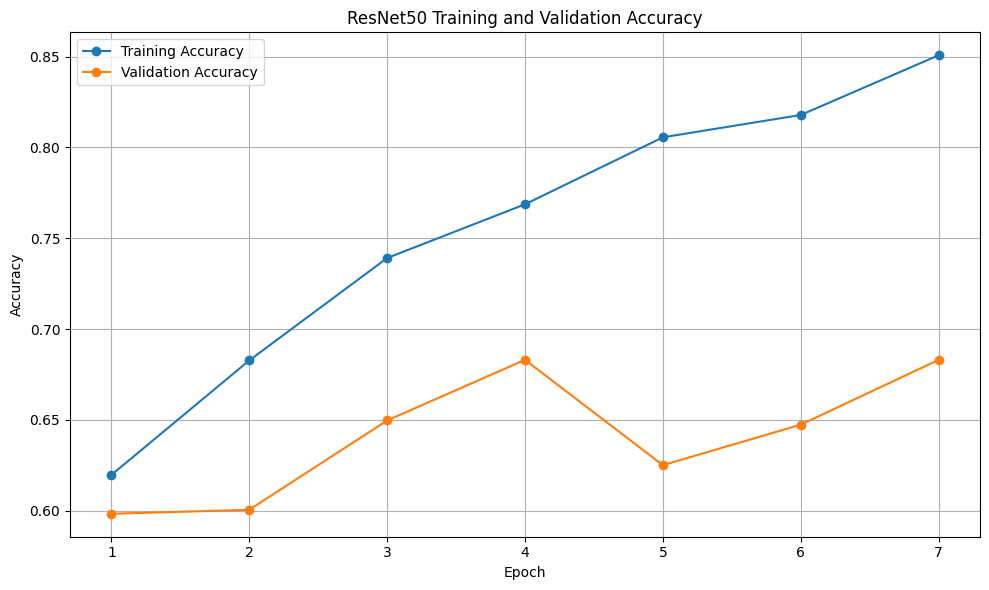

In [ ]:
resnet_train_acc = [
    0.6196, 0.6827, 0.7391,
    0.7687, 0.8056, 0.8179, 0.8508
]

resnet_val_acc = [
    0.5982, 0.6004, 0.6496,
    0.6830, 0.6250, 0.6473, 0.6830
]

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(resnet_train_acc)+1),
    resnet_train_acc,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    range(1, len(resnet_val_acc)+1),
    resnet_val_acc,
    marker='o',
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

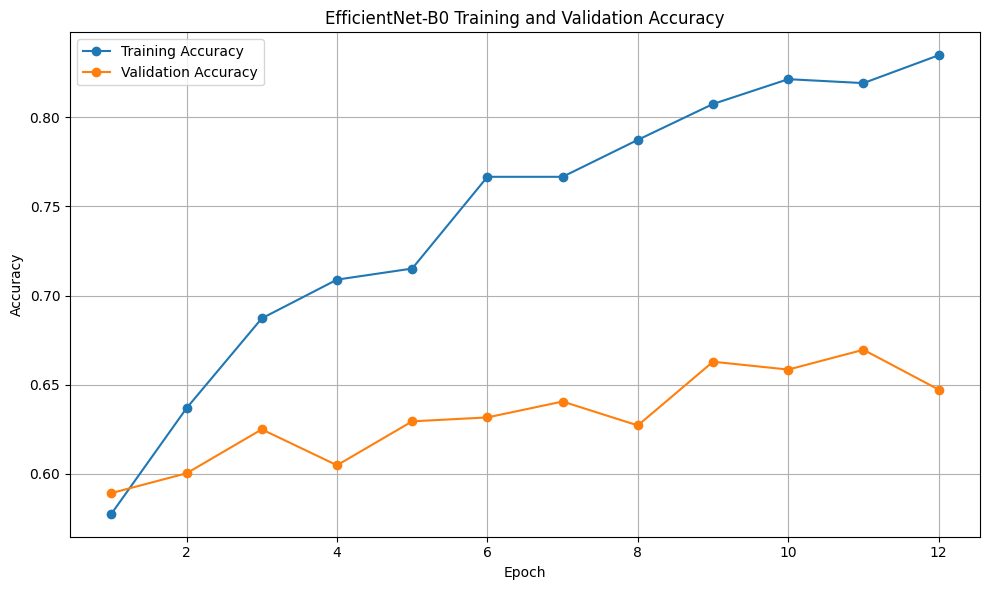

In [ ]:
efficientnet_train_acc = [
    0.5777, 0.6369, 0.6872, 0.7089,
    0.7151, 0.7665, 0.7665, 0.7872,
    0.8073, 0.8212, 0.8190, 0.8346
]

efficientnet_val_acc = [
    0.5893, 0.6004, 0.6250, 0.6049,
    0.6295, 0.6317, 0.6406, 0.6272,
    0.6629, 0.6585, 0.6696, 0.6473
]

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(efficientnet_train_acc)+1),
    efficientnet_train_acc,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    range(1, len(efficientnet_val_acc)+1),
    efficientnet_val_acc,
    marker='o',
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNet-B0 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

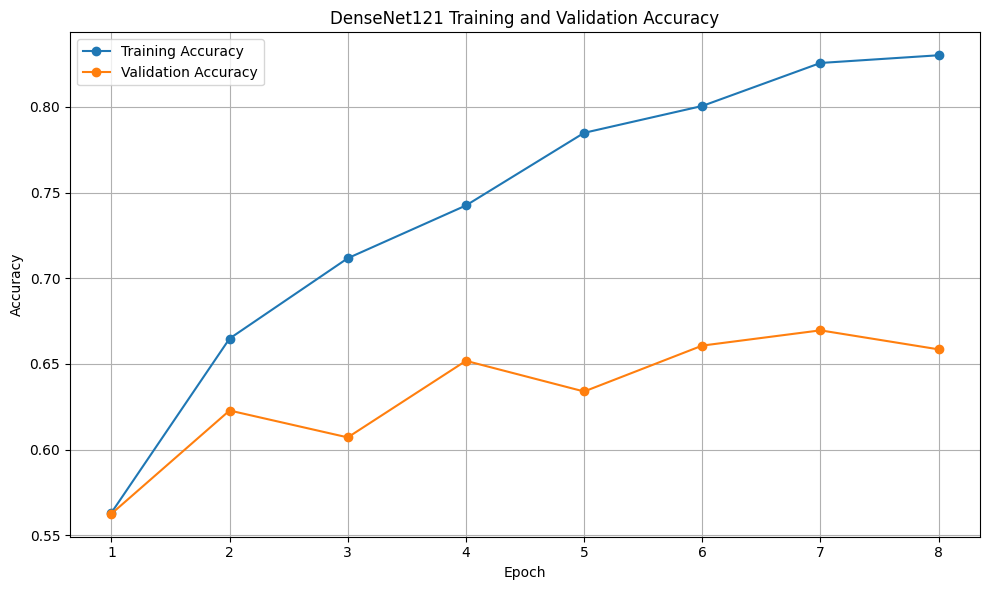

In [ ]:
densenet_train_acc = [
    0.5631, 0.6648, 0.7117, 0.7425,
    0.7849, 0.8006, 0.8257, 0.8302
]

densenet_val_acc = [
    0.5625, 0.6228, 0.6071, 0.6518,
    0.6339, 0.6607, 0.6696, 0.6585
]

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(densenet_train_acc)+1),
    densenet_train_acc,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    range(1, len(densenet_val_acc)+1),
    densenet_val_acc,
    marker='o',
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet121 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

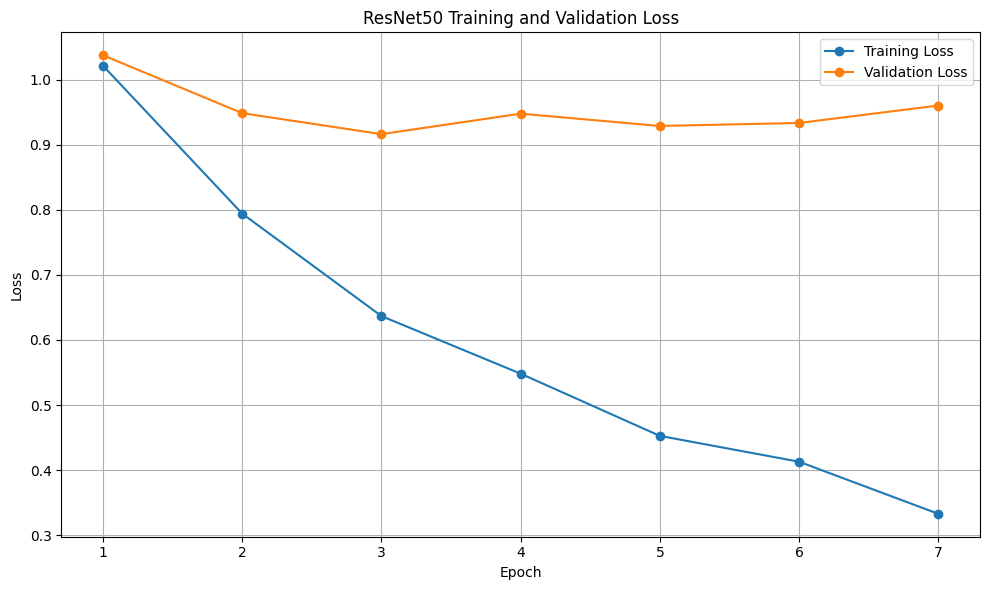

In [ ]:
resnet_train_loss = [
    1.0212, 0.7940, 0.6367,
    0.5482, 0.4527, 0.4130, 0.3330
]

resnet_val_loss = [
    1.0373, 0.9484, 0.9161,
    0.9476, 0.9287, 0.9333, 0.9601
]

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(resnet_train_loss)+1),
    resnet_train_loss,
    marker='o',
    label='Training Loss'
)

plt.plot(
    range(1, len(resnet_val_loss)+1),
    resnet_val_loss,
    marker='o',
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

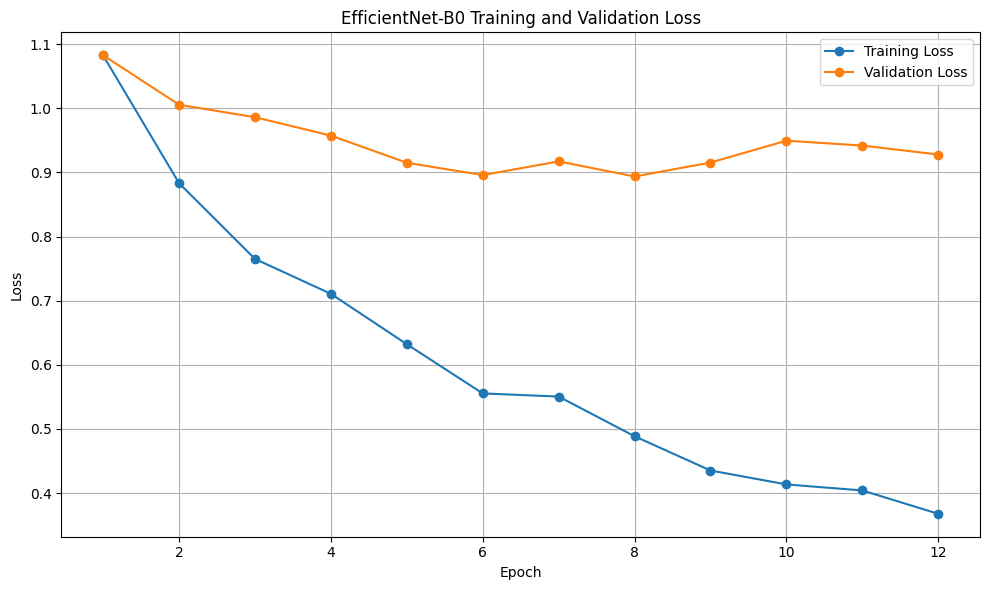

In [ ]:
efficientnet_train_loss = [
    1.0824, 0.8832, 0.7651, 0.7107,
    0.6321, 0.5554, 0.5505, 0.4886,
    0.4352, 0.4135, 0.4041, 0.3677
]

efficientnet_val_loss = [
    1.0827, 1.0055, 0.9861, 0.9574,
    0.9151, 0.8958, 0.9172, 0.8937,
    0.9154, 0.9495, 0.9419, 0.9279
]

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(efficientnet_train_loss)+1),
    efficientnet_train_loss,
    marker='o',
    label='Training Loss'
)

plt.plot(
    range(1, len(efficientnet_val_loss)+1),
    efficientnet_val_loss,
    marker='o',
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B0 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

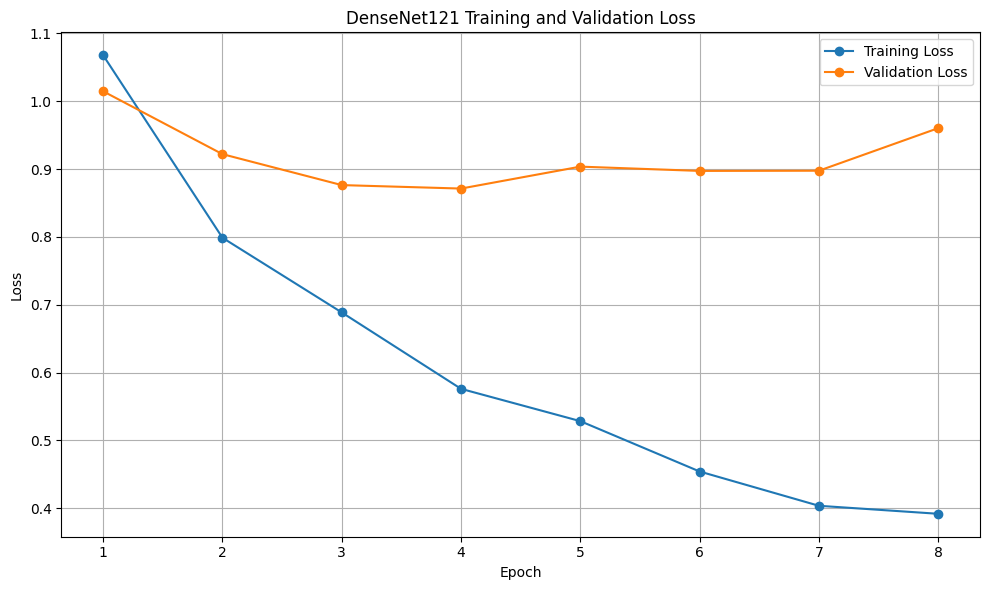

In [ ]:
densenet_train_loss = [
    1.0676, 0.7987, 0.6887, 0.5761,
    0.5285, 0.4543, 0.4038, 0.3920
]

densenet_val_loss = [
    1.0145, 0.9219, 0.8763, 0.8712,
    0.9035, 0.8972, 0.8975, 0.9602
]

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(densenet_train_loss)+1),
    densenet_train_loss,
    marker='o',
    label='Training Loss'
)

plt.plot(
    range(1, len(densenet_val_loss)+1),
    densenet_val_loss,
    marker='o',
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet121 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

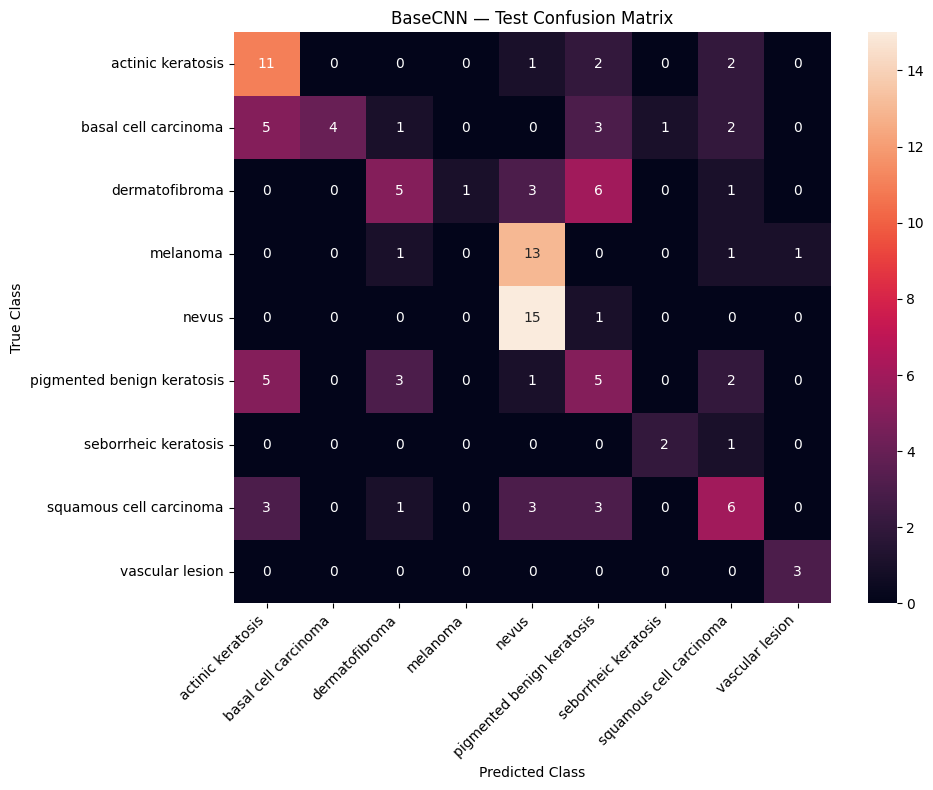

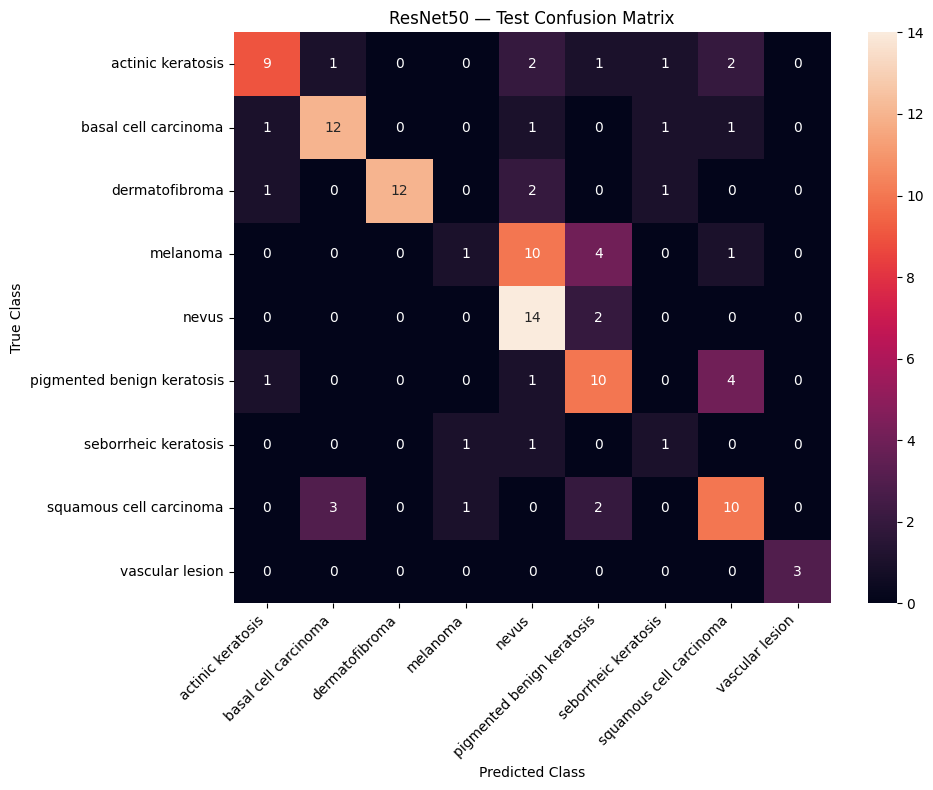

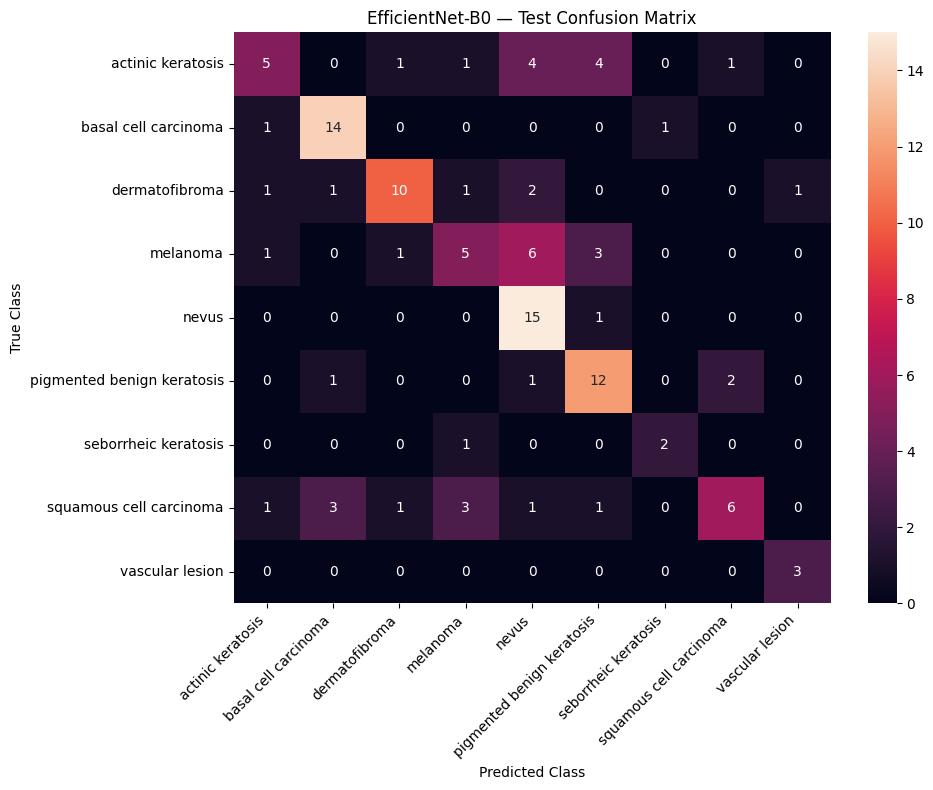

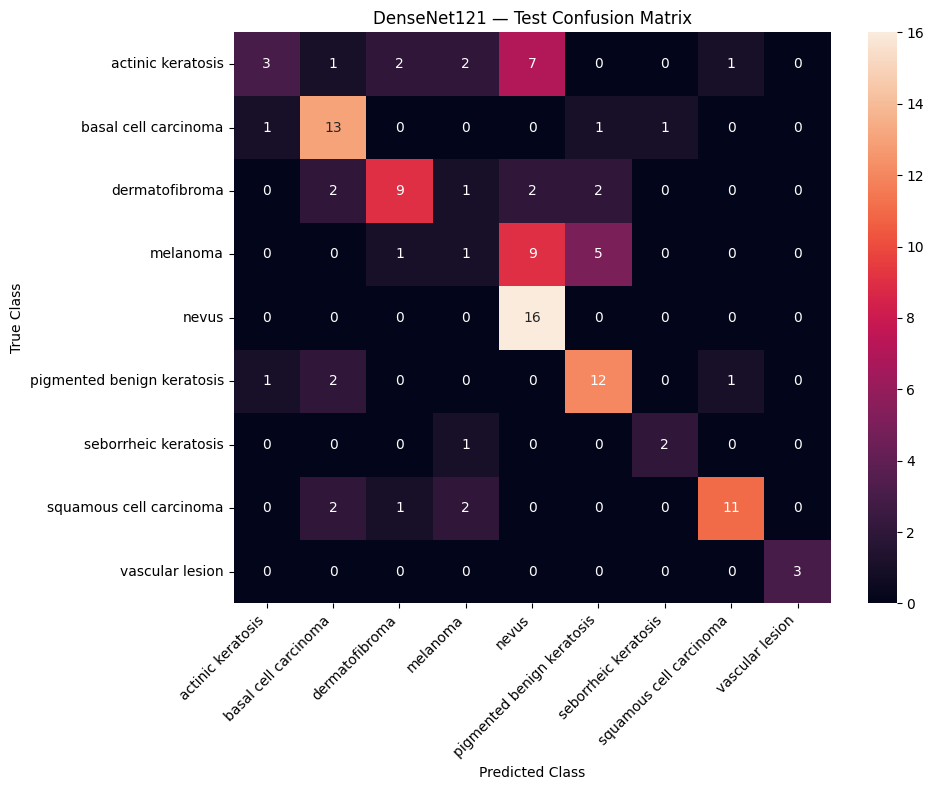

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

model_results = {
    "BaseCNN": base_results,
    "ResNet50": resnet_results,
    "EfficientNet-B0": efficientnet_results,
    "DenseNet121": densenet_results
}

for model_name, result in model_results.items():

    cm = result["cm"]

    plt.figure(figsize=(10,8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title(f"{model_name} — Test Confusion Matrix")

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

In [ ]:
sensitivity_df = pd.DataFrame({
    "Class": class_names,

    "BaseCNN": base_results["sensitivity_per_class"],

    "ResNet50": resnet_results["sensitivity_per_class"],

    "EfficientNet-B0": efficientnet_results["sensitivity_per_class"],

    "DenseNet121": densenet_results["sensitivity_per_class"]
})

sensitivity_df

,Class,BaseCNN,ResNet50,EfficientNet-B0,DenseNet121
0,actinic keratosis,0.687500,0.562500,0.312500,0.187500
1,basal cell carcinoma,0.250000,0.750000,0.875000,0.812500
2,dermatofibroma,0.312500,0.750000,0.625000,0.562500
3,melanoma,0.000000,0.062500,0.312500,0.062500
4,nevus,0.937500,0.875000,0.937500,1.000000
5,pigmented benign keratosis,0.312500,0.625000,0.750000,0.750000
6,seborrheic keratosis,0.666667,0.333333,0.666667,0.666667
7,squamous cell carcinoma,0.375000,0.625000,0.375000,0.687500
8,vascular lesion,1.000000,1.000000,1.000000,1.000000


In [ ]:
sensitivity_display = sensitivity_df.copy()

model_columns = [
    "BaseCNN",
    "ResNet50",
    "EfficientNet-B0",
    "DenseNet121"
]

sensitivity_display[model_columns] = (
    sensitivity_display[model_columns] * 100
).round(2)

sensitivity_display

,Class,BaseCNN,ResNet50,EfficientNet-B0,DenseNet121
0,actinic keratosis,68.75,56.25,31.25,18.75
1,basal cell carcinoma,25.00,75.00,87.50,81.25
2,dermatofibroma,31.25,75.00,62.50,56.25
3,melanoma,0.00,6.25,31.25,6.25
4,nevus,93.75,87.50,93.75,100.00
5,pigmented benign keratosis,31.25,62.50,75.00,75.00
6,seborrheic keratosis,66.67,33.33,66.67,66.67
7,squamous cell carcinoma,37.50,62.50,37.50,68.75
8,vascular lesion,100.00,100.00,100.00,100.00


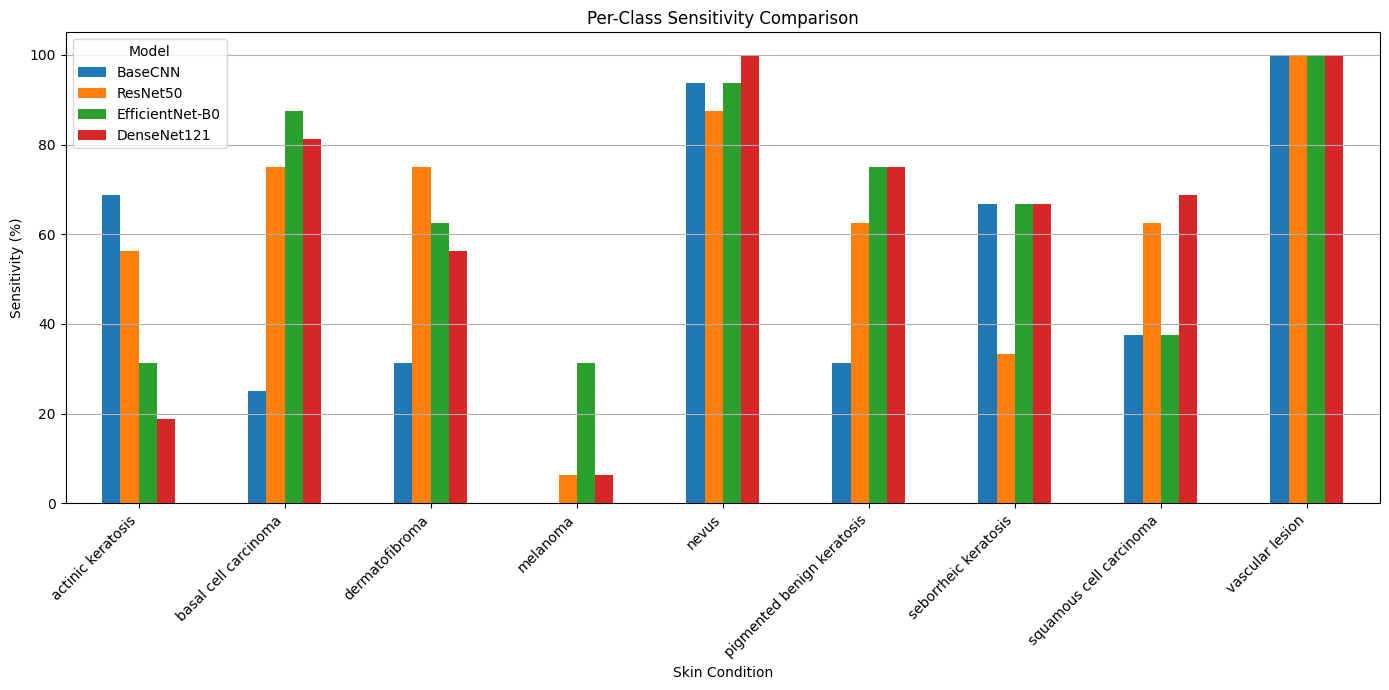

In [ ]:
sensitivity_plot = sensitivity_display.set_index("Class")

sensitivity_plot.plot(
    kind="bar",
    figsize=(14,7)
)

plt.xlabel("Skin Condition")
plt.ylabel("Sensitivity (%)")
plt.title("Per-Class Sensitivity Comparison")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Model")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

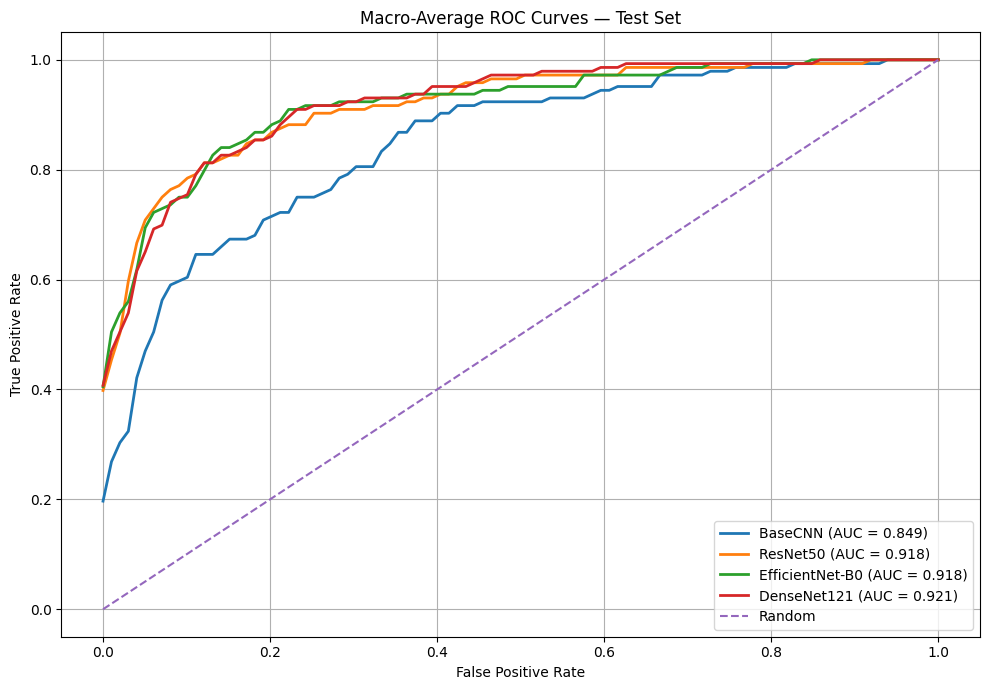

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10,7))

for model_name, result in model_results.items():

    y_true = result["y_true"]
    y_prob = result["y_prob"]

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES)
    )

    all_fpr = np.linspace(0, 1, 100)

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(NUM_CLASSES):

        fpr, tpr, _ = roc_curve(
            y_true_bin[:, i],
            y_prob[:, i]
        )

        mean_tpr += np.interp(
            all_fpr,
            fpr,
            tpr
        )

    mean_tpr /= NUM_CLASSES

    macro_auc = auc(
        all_fpr,
        mean_tpr
    )

    plt.plot(
        all_fpr,
        mean_tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {macro_auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Macro-Average ROC Curves — Test Set")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

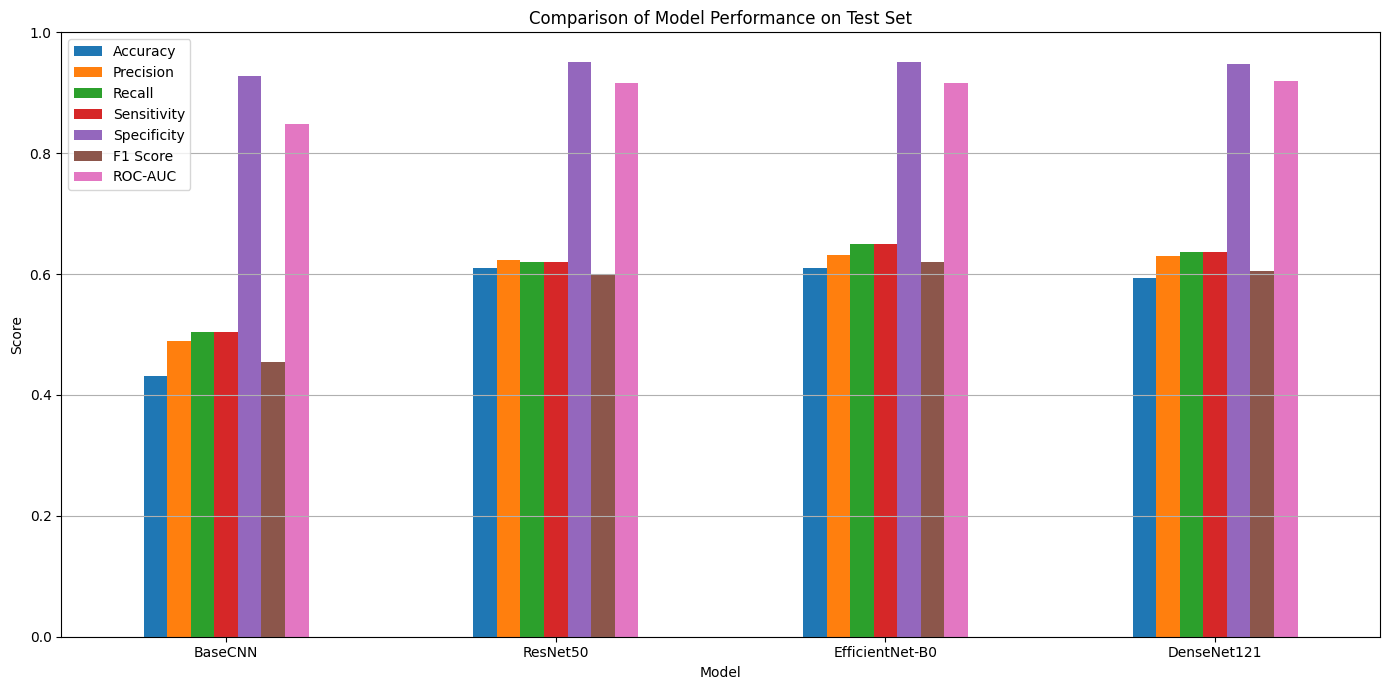

In [ ]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "Sensitivity",
    "Specificity",
    "F1 Score",
    "ROC-AUC"
]

plot_df = results_table.set_index("Model")[metrics_to_plot]

plot_df.plot(
    kind="bar",
    figsize=(14,7)
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Comparison of Model Performance on Test Set")

plt.xticks(rotation=0)
plt.ylim(0,1)
plt.legend()
plt.grid(axis="y")

plt.tight_layout()
plt.show()

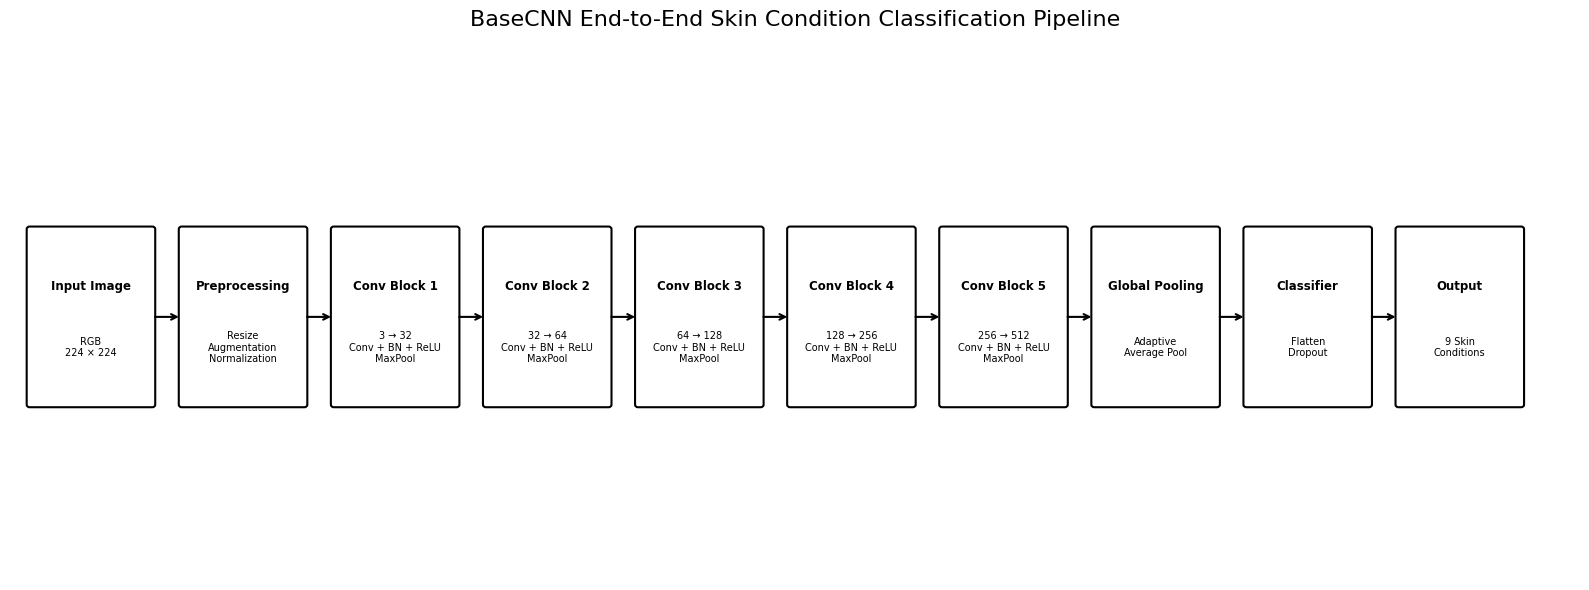

Pipeline saved to: /content/figures/basecnn_pipeline_diagram.png


In [ ]:
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

FIGURE_DIR = "/content/figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

fig, ax = plt.subplots(figsize=(16,6))

ax.set_xlim(0,16)
ax.set_ylim(0,6)
ax.axis("off")

steps = [

    ("Input Image",
     "RGB\n224 × 224"),

    ("Preprocessing",
     "Resize\nAugmentation\nNormalization"),

    ("Conv Block 1",
     "3 → 32\nConv + BN + ReLU\nMaxPool"),

    ("Conv Block 2",
     "32 → 64\nConv + BN + ReLU\nMaxPool"),

    ("Conv Block 3",
     "64 → 128\nConv + BN + ReLU\nMaxPool"),

    ("Conv Block 4",
     "128 → 256\nConv + BN + ReLU\nMaxPool"),

    ("Conv Block 5",
     "256 → 512\nConv + BN + ReLU\nMaxPool"),

    ("Global Pooling",
     "Adaptive\nAverage Pool"),

    ("Classifier",
     "Flatten\nDropout"),

    ("Output",
     "9 Skin\nConditions")
]

x_positions = [
    0.2, 1.75, 3.3, 4.85, 6.4,
    7.95, 9.5, 11.05, 12.6, 14.15
]

for i, ((title,text),x) in enumerate(
    zip(steps,x_positions)
):

    box = FancyBboxPatch(
        (x,2.0),
        1.25,
        2.0,
        boxstyle="round,pad=0.03",
        linewidth=1.5,
        fill=False
    )

    ax.add_patch(box)

    ax.text(
        x+0.625,
        3.35,
        title,
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold"
    )

    ax.text(
        x+0.625,
        2.65,
        text,
        ha="center",
        va="center",
        fontsize=7
    )

    if i < len(steps)-1:

        ax.annotate(
            "",
            xy=(x_positions[i+1],3.0),
            xytext=(x+1.25,3.0),
            arrowprops=dict(
                arrowstyle="->",
                linewidth=1.5
            )
        )

ax.set_title(
    "BaseCNN End-to-End Skin Condition Classification Pipeline",
    fontsize=16,
    pad=20
)

plt.tight_layout()

pipeline_path = os.path.join(
    FIGURE_DIR,
    "basecnn_pipeline_diagram.png"
)

plt.savefig(
    pipeline_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Pipeline saved to:", pipeline_path)

In [ ]:
hyperparameters = pd.DataFrame({

    "Parameter": [
        "Dataset",
        "Number of Classes",
        "Input Image Size",
        "Batch Size",
        "Train/Validation Split",
        "Data Augmentation",
        "Normalization",
        "Loss Function",
        "Class Weighting",
        "Optimizer",
        "Stage 1 Learning Rate",
        "Fine-tuning Learning Rate",
        "Early Stopping",
        "Hardware"
    ],

    "Value": [
        "ISIC 2019 subset",
        "9",
        "224 × 224",
        "32",
        "80% / 20%",
        "Horizontal Flip, Vertical Flip, Rotation, Color Jitter",
        "ImageNet Mean / Standard Deviation",
        "Weighted Cross Entropy",
        "Balanced Class Weights",
        "Adam",
        "0.001",
        "0.0001",
        "Patience 3–4",
        "NVIDIA Tesla T4"
    ]
})

hyperparameters

,Parameter,Value
0,Dataset,ISIC 2019 subset
1,Number of Classes,9
2,Input Image Size,224 × 224
3,Batch Size,32
4,Train/Validation Split,80% / 20%
5,Data Augmentation,"Horizontal Flip, Vertical Flip, Rotation, Colo..."
6,Normalization,ImageNet Mean / Standard Deviation
7,Loss Function,Weighted Cross Entropy
8,Class Weighting,Balanced Class Weights
9,Optimizer,Adam


In [ ]:
architecture_df = pd.DataFrame({

    "Model": [
        "BaseCNN",
        "ResNet50",
        "EfficientNet-B0",
        "DenseNet121"
    ],

    "Architecture Type": [
        "Custom CNN",
        "Residual CNN",
        "Efficient CNN",
        "Dense Connectivity CNN"
    ],

    "Pretrained": [
        "No",
        "ImageNet",
        "ImageNet",
        "ImageNet"
    ],

    "Input": [
        "224 × 224 × 3",
        "224 × 224 × 3",
        "224 × 224 × 3",
        "224 × 224 × 3"
    ],

    "Output Classes": [
        9, 9, 9, 9
    ]
})

architecture_df

,Model,Architecture Type,Pretrained,Input,Output Classes
0,BaseCNN,Custom CNN,No,224 × 224 × 3,9
1,ResNet50,Residual CNN,ImageNet,224 × 224 × 3,9
2,EfficientNet-B0,Efficient CNN,ImageNet,224 × 224 × 3,9
3,DenseNet121,Dense Connectivity CNN,ImageNet,224 × 224 × 3,9


In [ ]:
study_comparison = pd.DataFrame({

    "Method": [
        "BaseCNN",
        "ResNet50",
        "EfficientNet-B0",
        "DenseNet121",
        "Published Study - Individual Models",
        "Published Study - Ensemble Average",
        "Published Study - Optimal Ensemble"
    ],

    "Mean Sensitivity (%)": [

        base_results["sensitivity"] * 100,

        resnet_results["sensitivity"] * 100,

        efficientnet_results["sensitivity"] * 100,

        densenet_results["sensitivity"] * 100,

        68.8,

        71.7,

        72.5
    ]
})

study_comparison

,Method,Mean Sensitivity (%)
0,BaseCNN,50.462963
1,ResNet50,62.037037
2,EfficientNet-B0,65.046296
3,DenseNet121,63.657407
4,Published Study - Individual Models,68.800000
5,Published Study - Ensemble Average,71.700000
6,Published Study - Optimal Ensemble,72.500000


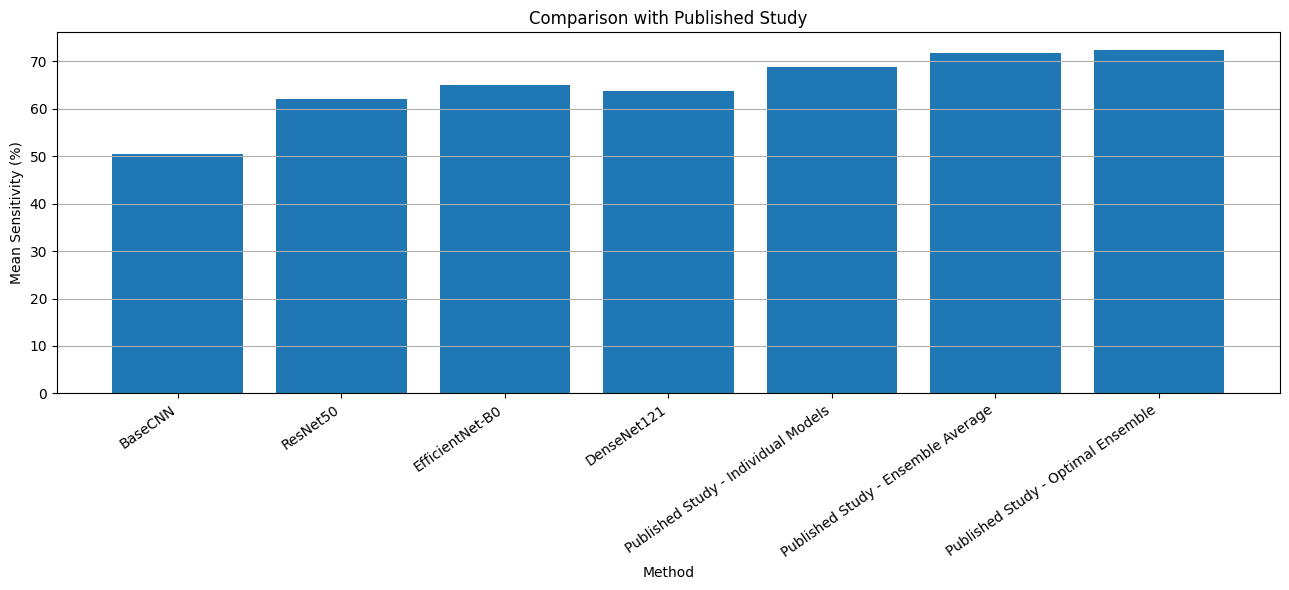

In [ ]:
plt.figure(figsize=(13,6))

plt.bar(
    study_comparison["Method"],
    study_comparison["Mean Sensitivity (%)"]
)

plt.ylabel("Mean Sensitivity (%)")
plt.xlabel("Method")

plt.title(
    "Comparison with Published Study"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.grid(axis="y")

plt.tight_layout()
plt.show()

In [ ]:
best_accuracy = results_table.loc[
    results_table["Accuracy"].idxmax()
]

best_sensitivity = results_table.loc[
    results_table["Sensitivity"].idxmax()
]

best_f1 = results_table.loc[
    results_table["F1 Score"].idxmax()
]

best_auc = results_table.loc[
    results_table["ROC-AUC"].idxmax()
]

print("Best Accuracy:")
print(
    best_accuracy["Model"],
    f"({best_accuracy['Accuracy']:.2%})"
)

print("\nBest Sensitivity:")
print(
    best_sensitivity["Model"],
    f"({best_sensitivity['Sensitivity']:.2%})"
)

print("\nBest F1 Score:")
print(
    best_f1["Model"],
    f"({best_f1['F1 Score']:.2%})"
)

print("\nBest ROC-AUC:")
print(
    best_auc["Model"],
    f"({best_auc['ROC-AUC']:.3f})"
)

Best Accuracy:
ResNet50 (61.02%)

Best Sensitivity:
EfficientNet-B0 (65.05%)

Best F1 Score:
EfficientNet-B0 (61.99%)

Best ROC-AUC:
DenseNet121 (0.920)


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import shutil

# ============================================================
# FINAL RESULTS DIRECTORY
# ============================================================

RESULTS_DIR = "/content/Final_Project_Results"

FIGURE_DIR = os.path.join(RESULTS_DIR, "Figures")
TABLE_DIR = os.path.join(RESULTS_DIR, "Tables")
REPORT_DIR = os.path.join(RESULTS_DIR, "Reports")

os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

print("Final results folders created.")

Final results folders created.


In [ ]:
results_table_display.to_csv(
    os.path.join(TABLE_DIR, "Final_Test_Results.csv"),
    index=False
)

results_table_display.to_excel(
    os.path.join(TABLE_DIR, "Final_Test_Results.xlsx"),
    index=False
)

print("Test results saved.")

Test results saved.


In [ ]:
results_table_display.to_csv(
    os.path.join(TABLE_DIR, "Final_Test_Results.csv"),
    index=False
)

results_table_display.to_excel(
    os.path.join(TABLE_DIR, "Final_Test_Results.xlsx"),
    index=False
)

print("Test results saved.")

Test results saved.


In [ ]:
sensitivity_display.to_csv(
    os.path.join(TABLE_DIR, "Per_Class_Sensitivity.csv"),
    index=False
)

sensitivity_display.to_excel(
    os.path.join(TABLE_DIR, "Per_Class_Sensitivity.xlsx"),
    index=False
)

print("Sensitivity table saved.")

Sensitivity table saved.


In [ ]:
study_comparison = pd.DataFrame({

    "Method": [
        "BaseCNN",
        "ResNet50",
        "EfficientNet-B0",
        "DenseNet121",
        "Published Study - Best Individual",
        "Published Study - Ensemble Average",
        "Published Study - Optimal Ensemble"
    ],

    "Mean Sensitivity (%)": [
        base_results["sensitivity"] * 100,
        resnet_results["sensitivity"] * 100,
        efficientnet_results["sensitivity"] * 100,
        densenet_results["sensitivity"] * 100,
        68.8,
        71.7,
        72.5
    ]
})

study_comparison["Mean Sensitivity (%)"] = (
    study_comparison["Mean Sensitivity (%)"].round(2)
)

study_comparison

,Method,Mean Sensitivity (%)
0,BaseCNN,50.46
1,ResNet50,62.04
2,EfficientNet-B0,65.05
3,DenseNet121,63.66
4,Published Study - Best Individual,68.80
5,Published Study - Ensemble Average,71.70
6,Published Study - Optimal Ensemble,72.50


In [ ]:
study_comparison.to_csv(
    os.path.join(TABLE_DIR, "Study_Comparison.csv"),
    index=False
)

study_comparison.to_excel(
    os.path.join(TABLE_DIR, "Study_Comparison.xlsx"),
    index=False
)

In [ ]:
for model_name, result in model_results.items():

    report = classification_report(
        result["y_true"],
        result["y_pred"],
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    )

    report_path = os.path.join(
        REPORT_DIR,
        f"{model_name}_Classification_Report.txt"
    )

    with open(report_path, "w") as f:
        f.write(f"{model_name} - Test Classification Report\n")
        f.write("=" * 70 + "\n\n")
        f.write(report)

print("Classification reports saved.")

Classification reports saved.


In [ ]:
for model_name, result in model_results.items():

    cm = result["cm"]

    plt.figure(figsize=(10,8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title(f"{model_name} - Test Confusion Matrix")

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()

    save_path = os.path.join(
        FIGURE_DIR,
        f"{model_name}_Confusion_Matrix.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("Confusion matrices saved.")

Confusion matrices saved.


In [ ]:
plt.figure(figsize=(10,7))

for model_name, result in model_results.items():

    y_true = result["y_true"]
    y_prob = result["y_prob"]

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES)
    )

    all_fpr = np.linspace(0, 1, 100)
    mean_tpr = np.zeros_like(all_fpr)

    for i in range(NUM_CLASSES):

        fpr, tpr, _ = roc_curve(
            y_true_bin[:, i],
            y_prob[:, i]
        )

        mean_tpr += np.interp(
            all_fpr,
            fpr,
            tpr
        )

    mean_tpr /= NUM_CLASSES

    macro_auc = auc(
        all_fpr,
        mean_tpr
    )

    plt.plot(
        all_fpr,
        mean_tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {macro_auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Macro-Average ROC Curves - Test Set")

plt.legend()
plt.grid(True)

plt.tight_layout()

roc_path = os.path.join(
    FIGURE_DIR,
    "ROC_AUC_Comparison.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("ROC-AUC graph saved.")

ROC-AUC graph saved.


In [ ]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "Sensitivity",
    "Specificity",
    "F1 Score",
    "ROC-AUC"
]

plot_df = results_table.set_index("Model")[metrics_to_plot]

plt.figure(figsize=(14,7))

plot_df.plot(
    kind="bar",
    figsize=(14,7)
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Comparison of Model Performance on Test Set")

plt.xticks(rotation=0)
plt.ylim(0,1)
plt.legend()
plt.grid(axis="y")

plt.tight_layout()

comparison_path = os.path.join(
    FIGURE_DIR,
    "Model_Performance_Comparison.png"
)

plt.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Model comparison graph saved.")

Model comparison graph saved.


<Figure size 1400x700 with 0 Axes>

In [ ]:
plt.figure(figsize=(14,7))

sensitivity_plot = sensitivity_display.set_index("Class")

sensitivity_plot.plot(
    kind="bar",
    figsize=(14,7)
)

plt.xlabel("Skin Condition")
plt.ylabel("Sensitivity (%)")
plt.title("Per-Class Sensitivity Comparison")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Model")
plt.grid(axis="y")

plt.tight_layout()

sensitivity_path = os.path.join(
    FIGURE_DIR,
    "Per_Class_Sensitivity_Comparison.png"
)

plt.savefig(
    sensitivity_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Sensitivity graph saved.")

Sensitivity graph saved.


<Figure size 1400x700 with 0 Axes>

In [ ]:
plt.figure(figsize=(13,6))

plt.bar(
    study_comparison["Method"],
    study_comparison["Mean Sensitivity (%)"]
)

plt.ylabel("Mean Sensitivity (%)")
plt.xlabel("Method")

plt.title(
    "Comparison with Published Study"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.grid(axis="y")

plt.tight_layout()

study_path = os.path.join(
    FIGURE_DIR,
    "Study_Comparison.png"
)

plt.savefig(
    study_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Study comparison graph saved.")

Study comparison graph saved.


In [ ]:
if os.path.exists(pipeline_path):

    shutil.copy(
        pipeline_path,
        os.path.join(
            FIGURE_DIR,
            "BaseCNN_Pipeline_Diagram.png"
        )
    )

    print("Pipeline diagram copied.")
else:
    print("Pipeline diagram not found.")

Pipeline diagram copied.


In [ ]:
summary_path = os.path.join(
    REPORT_DIR,
    "Final_Project_Summary.txt"
)

with open(summary_path, "w") as f:

    f.write("SKIN CONDITION CLASSIFICATION PROJECT\n")
    f.write("=" * 70 + "\n\n")

    f.write("Models Evaluated\n")
    f.write("-" * 70 + "\n")
    f.write("1. BaseCNN\n")
    f.write("2. ResNet50\n")
    f.write("3. EfficientNet-B0\n")
    f.write("4. DenseNet121\n\n")

    f.write("Dataset\n")
    f.write("-" * 70 + "\n")
    f.write("Clean training-pool images: 2238\n")
    f.write("Training images: 1790\n")
    f.write("Validation images: 448\n")
    f.write("Test images: 118\n")
    f.write("Number of classes: 9\n\n")

    f.write("TEST RESULTS\n")
    f.write("=" * 70 + "\n\n")

    f.write(
        results_table_display.to_string(index=False)
    )

    f.write("\n\nSTUDY COMPARISON\n")
    f.write("=" * 70 + "\n\n")

    f.write(
        study_comparison.to_string(index=False)
    )

print("Summary saved.")

Summary saved.


In [ ]:
zip_path = shutil.make_archive(
    "/content/Final_Project_Results",
    "zip",
    RESULTS_DIR
)

print("==========================================")
print("EVERYTHING SAVED SUCCESSFULLY")
print("==========================================")
print(zip_path)

EVERYTHING SAVED SUCCESSFULLY
/content/Final_Project_Results.zip


In [ ]:
from google.colab import files

files.download(
    "/content/Final_Project_Results.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

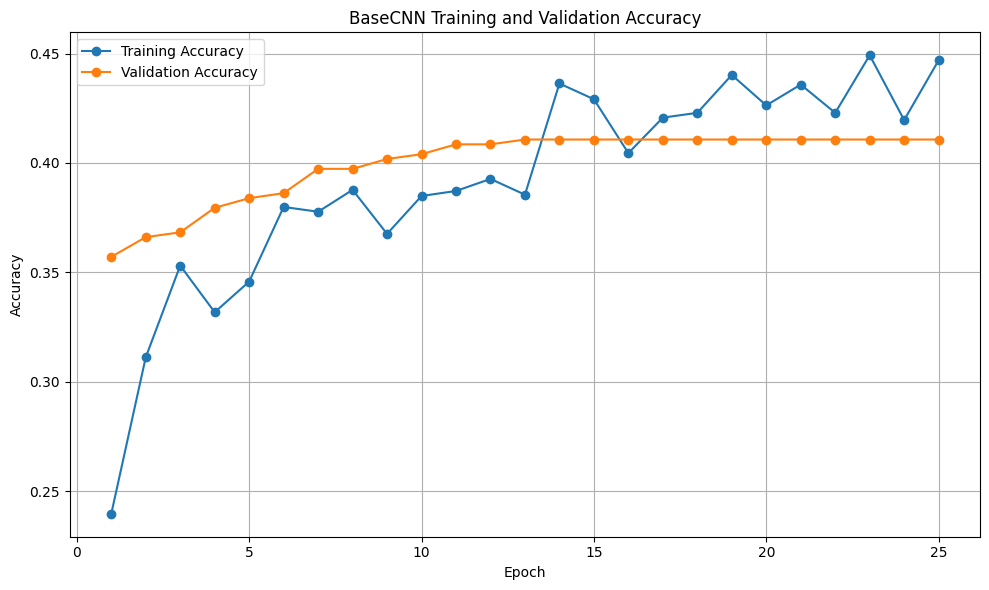

In [ ]:
import matplotlib.pyplot as plt

cnn_train_acc = [
    0.2397, 0.3112, 0.3531, 0.3318, 0.3458,
    0.3799, 0.3777, 0.3877, 0.3676, 0.3849,
    0.3872, 0.3927, 0.3855, 0.4363, 0.4291,
    0.4045, 0.4207, 0.4229, 0.4402, 0.4263,
    0.4358, 0.4229, 0.4492, 0.4196, 0.4469
]

cnn_val_acc = [
    0.3571, 0.3661, 0.3683, 0.3795, 0.3839,
    0.3862, 0.3973, 0.3973, 0.4018, 0.4040,
    0.4085, 0.4085, 0.4107, 0.4107, 0.4107,
    0.4107, 0.4107, 0.4107, 0.4107, 0.4107,
    0.4107, 0.4107, 0.4107, 0.4107, 0.4107
]

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(cnn_train_acc)+1),
    cnn_train_acc,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    range(1, len(cnn_val_acc)+1),
    cnn_val_acc,
    marker='o',
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("BaseCNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import os

In [ ]:
cnn_acc_path = os.path.join(
    FIGURE_DIR,
    "BaseCNN_Training_Validation_Accuracy.png"
)

plt.savefig(
    cnn_acc_path,
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, 26)

plt.figure(figsize=(8, 5))

plt.plot(epochs, cnn_train_loss, label='Training Loss')
plt.plot(epochs, cnn_val_loss, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN Training and Validation Loss')
plt.legend()
plt.grid(True)

plt.show()

NameError: name 'cnn_train_loss' is not defined

<Figure size 800x500 with 0 Axes>

In [ ]:
[x for x in globals() if 'loss' in x.lower()]

['best_val_loss',
 'train_loss',
 'loss',
 'val_loss',
 'resnet_train_loss',
 'resnet_val_loss',
 'efficientnet_train_loss',
 'efficientnet_val_loss',
 'densenet_train_loss',
 'densenet_val_loss']

In [ ]:
print("cnn_train_acc:", len(cnn_train_acc))
print("cnn_val_acc:", len(cnn_val_acc))

print("cnn_train_loss" in globals())
print("cnn_val_loss" in globals())

cnn_train_acc: 25
cnn_val_acc: 25
False
False


In [ ]:
print(cnn_train_loss)
print(cnn_val_loss)

NameError: name 'cnn_train_loss' is not defined

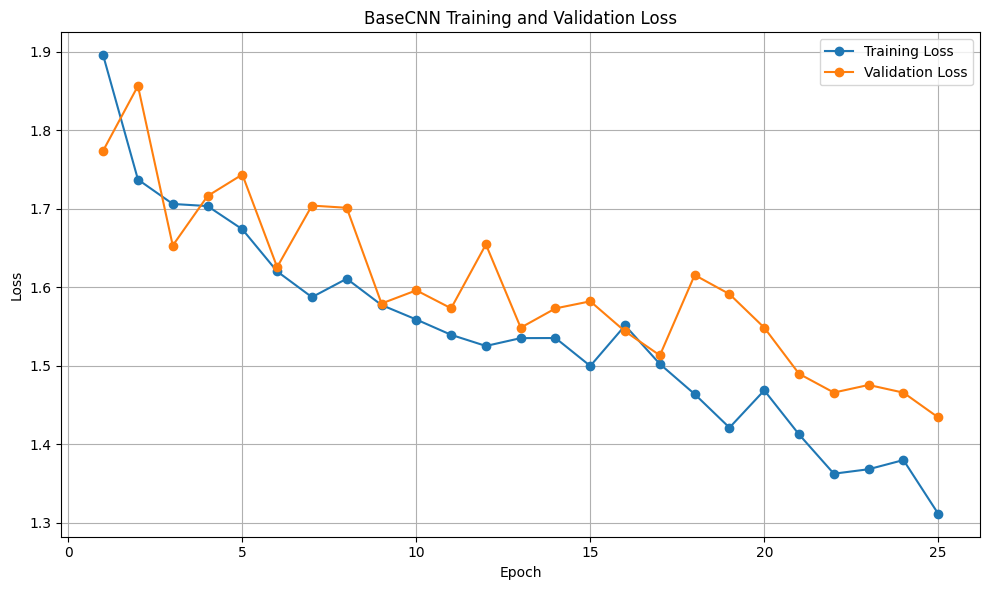

In [ ]:
import matplotlib.pyplot as plt

cnn_train_loss = [
    1.8958, 1.7374, 1.7063, 1.7036, 1.6740,
    1.6203, 1.5875, 1.6110, 1.5775, 1.5590,
    1.5395, 1.5253, 1.5353, 1.5354, 1.4998,
    1.5514, 1.5023, 1.4639, 1.4212, 1.4687,
    1.4125, 1.3625, 1.3682, 1.3799, 1.3114
]

cnn_val_loss = [
    1.7742, 1.8567, 1.6533, 1.7164, 1.7438,
    1.6258, 1.7042, 1.7014, 1.5794, 1.5962,
    1.5733, 1.6547, 1.5486, 1.5732, 1.5822,
    1.5439, 1.5133, 1.6157, 1.5914, 1.5486,
    1.4898, 1.4659, 1.4756, 1.4658, 1.4342
]

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(cnn_train_loss)+1),
    cnn_train_loss,
    marker='o',
    label='Training Loss'
)

plt.plot(
    range(1, len(cnn_val_loss)+1),
    cnn_val_loss,
    marker='o',
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BaseCNN Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

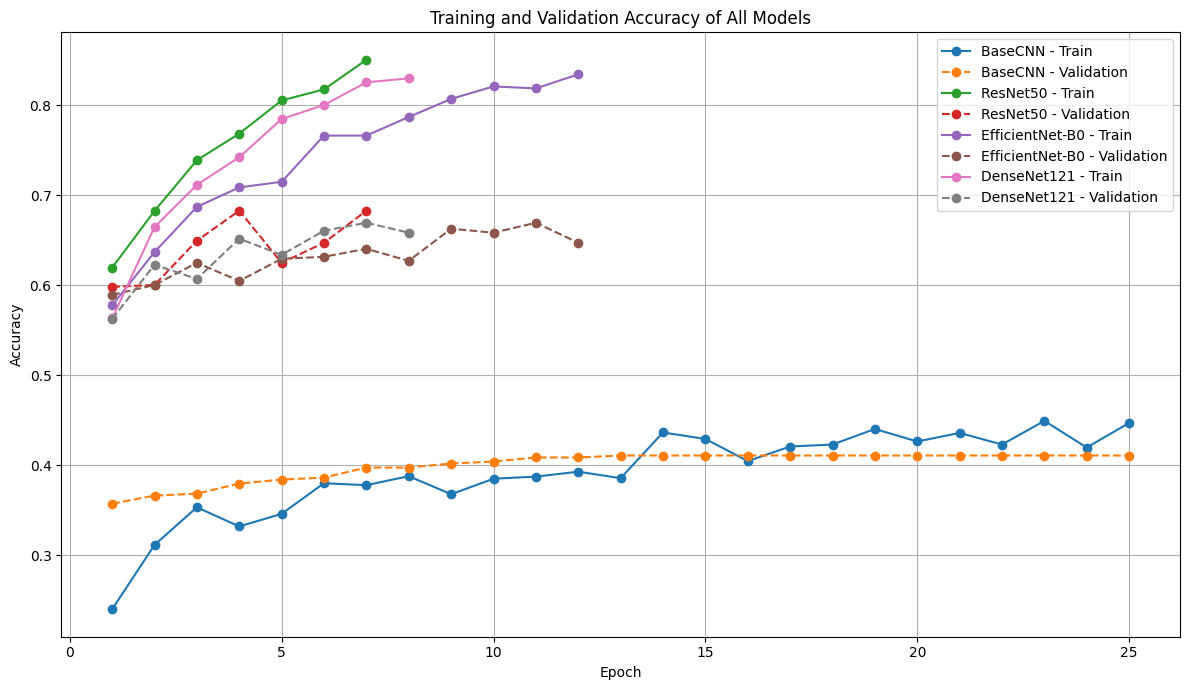

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

# BaseCNN
plt.plot(range(1, len(cnn_train_acc)+1),
         cnn_train_acc,
         marker='o',
         label='BaseCNN - Train')

plt.plot(range(1, len(cnn_val_acc)+1),
         cnn_val_acc,
         marker='o',
         linestyle='--',
         label='BaseCNN - Validation')


# ResNet50
plt.plot(range(1, len(resnet_train_acc)+1),
         resnet_train_acc,
         marker='o',
         label='ResNet50 - Train')

plt.plot(range(1, len(resnet_val_acc)+1),
         resnet_val_acc,
         marker='o',
         linestyle='--',
         label='ResNet50 - Validation')


# EfficientNet-B0
plt.plot(range(1, len(efficientnet_train_acc)+1),
         efficientnet_train_acc,
         marker='o',
         label='EfficientNet-B0 - Train')

plt.plot(range(1, len(efficientnet_val_acc)+1),
         efficientnet_val_acc,
         marker='o',
         linestyle='--',
         label='EfficientNet-B0 - Validation')


# DenseNet121
plt.plot(range(1, len(densenet_train_acc)+1),
         densenet_train_acc,
         marker='o',
         label='DenseNet121 - Train')

plt.plot(range(1, len(densenet_val_acc)+1),
         densenet_val_acc,
         marker='o',
         linestyle='--',
         label='DenseNet121 - Validation')


plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy of All Models")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/Final_Project_Results/Figures/all_models_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

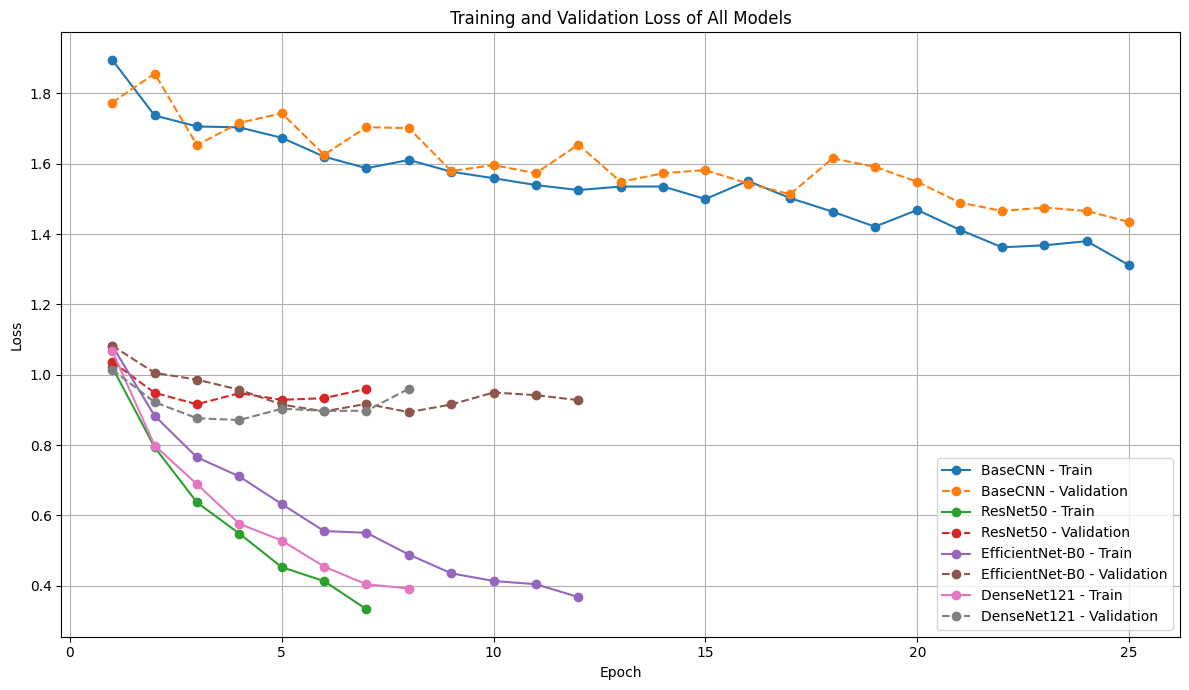

In [ ]:
plt.figure(figsize=(12, 7))

# BaseCNN
plt.plot(range(1, len(cnn_train_loss)+1),
         cnn_train_loss,
         marker='o',
         label='BaseCNN - Train')

plt.plot(range(1, len(cnn_val_loss)+1),
         cnn_val_loss,
         marker='o',
         linestyle='--',
         label='BaseCNN - Validation')


# ResNet50
plt.plot(range(1, len(resnet_train_loss)+1),
         resnet_train_loss,
         marker='o',
         label='ResNet50 - Train')

plt.plot(range(1, len(resnet_val_loss)+1),
         resnet_val_loss,
         marker='o',
         linestyle='--',
         label='ResNet50 - Validation')


# EfficientNet-B0
plt.plot(range(1, len(efficientnet_train_loss)+1),
         efficientnet_train_loss,
         marker='o',
         label='EfficientNet-B0 - Train')

plt.plot(range(1, len(efficientnet_val_loss)+1),
         efficientnet_val_loss,
         marker='o',
         linestyle='--',
         label='EfficientNet-B0 - Validation')


# DenseNet121
plt.plot(range(1, len(densenet_train_loss)+1),
         densenet_train_loss,
         marker='o',
         label='DenseNet121 - Train')

plt.plot(range(1, len(densenet_val_loss)+1),
         densenet_val_loss,
         marker='o',
         linestyle='--',
         label='DenseNet121 - Validation')


plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss of All Models")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/Final_Project_Results/Figures/all_models_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import os

print(os.path.exists(
    "/content/Final_Project_Results/Figures/all_models_accuracy.png"
))

print(os.path.exists(
    "/content/Final_Project_Results/Figures/all_models_loss.png"
))

True
True


In [ ]:
import shutil
import os

# Remove old zip if it exists
zip_path = "/content/Final_Project_Results"

shutil.make_archive(
    "/content/Final_Project_Results",
    "zip",
    "/content",
    "Final_Project_Results"
)

print("ZIP created successfully!")
print(os.path.getsize("/content/Final_Project_Results.zip") / (1024*1024), "MB")

ZIP created successfully!
2.4849376678466797 MB


In [ ]:
from google.colab import files

files.download("/content/Final_Project_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>